# Lab 5 VAE Experiment 5: Improved Fashion MNIST VAE Architecture

This notebook tests an improved VAE architecture for Fashion MNIST.

From Experiment 2, 3 and 4, `latent_dim = 3` was selected as a balanced and interpretable latent dimension because it provides a compact 3D latent space for further analysis.

In this experiment, the latent dimension is kept at `3`, while the encoder and decoder architecture are improved. This allows us to test whether improving the model architecture can improve reconstruction and generation quality without changing the selected latent dimension.

# 1. Control GPU memory usage.

In [1]:
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# 2. Import libraries
The required libraries are imported below. The Keras session is also cleared to prevent memory issues from previous model runs.

In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import gc
import tensorflow as tf
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt

keras.backend.clear_session()
gc.collect()

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

# 3. Sampling Layer
## This is to generate values according to the standard normal distribution, for neurons in the latent layer.
The Sampling layer creates the latent vector `z` from `z_mean` and `z_log_var`. This allows the VAE to learn a smooth latent space and generate new images from sampled latent values.

In [3]:
class Sampling(layers.Layer):
    """Uses (z_mean, z_log_var) to sample z, the vector encoding a digit."""

    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = tf.random.normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# 4. Build Improved Encoder

The improved encoder compresses each 28 × 28 Fashion MNIST image into a 3-dimensional latent representation.

Compared to the original encoder, an extra convolutional layer is added to increase the model’s ability to extract image features. The latent dimension is kept as `3` because it was selected as a balanced and interpretable setting in the previous experiment.

In [4]:
latent_dim = 3   # Use the selected balanced latent dimension from Experiment 2, 3 and 4

encoder_inputs = keras.Input(shape=(28, 28, 1))

# Encoder block 1
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)

# Encoder block 2
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)

x = layers.Flatten()(x)
x = layers.Dense(32, activation="relu")(x)

z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 28, 28, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 14, 14, 32)   320         ['input_1[0][0]']                
                                                                                                  
 conv2d_1 (Conv2D)              (None, 14, 14, 32)   9248        ['conv2d[0][0]']                 
                                                                                                  
 conv2d_2 (Conv2D)              (None, 7, 7, 64)     18496       ['conv2d_1[0][0]']               
                                                                                            

### Encoder Architecture Observation

The improved encoder outputs `z_mean`, `z_log_var`, and `z`, each with shape `(None, 3)`. This confirms that the improved VAE is using the selected `latent_dim = 3`.

The additional convolutional layer gives the encoder more capacity to learn Fashion MNIST image features.

# 5. Build Improved Decoder

The improved decoder reconstructs a 28 × 28 grayscale Fashion MNIST image from the 3-dimensional latent vector.

Compared to the original decoder, an extra Conv2DTranspose layer is added to improve reconstruction and generation quality.

In [5]:
latent_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)

# Decoder block 1
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)

# Extra decoder layer
x = layers.Conv2DTranspose(32, 3, activation="relu", padding="same")(x)

# Decoder block 2
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)

decoder_outputs = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 3)]               0         
                                                                 
 dense_1 (Dense)             (None, 3136)              12544     
                                                                 
 reshape (Reshape)           (None, 7, 7, 64)          0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 14, 14, 64)       36928     
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 14, 14, 32)       18464     
 ranspose)                                                       
                                                                 
 conv2d_transpose_2 (Conv2DT  (None, 28, 28, 32)       9248

### Decoder Architecture Observation

The improved decoder takes an input with shape `(None, 3)` and reconstructs it into a 28 × 28 × 1 image. The extra decoder layer gives the model more capacity to generate clearer Fashion MNIST-like images.

# 6. Build VAE Model
## This part of the code defines a VAE object (as a class), and the training process.

The VAE combines the encoder and decoder. It is trained using reconstruction loss and KL loss. Reconstruction loss measures how well the image is reconstructed, while KL loss regularises the latent space.

In [6]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstruction = self.decoder(z)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(data, reconstruction),
                    axis=(1, 2),
                )
            )
            kl_loss = -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var))
            kl_loss = tf.reduce_mean(tf.reduce_sum(kl_loss, axis=1))
            total_loss = reconstruction_loss + kl_loss
        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

# 7. Train Improved VAE on Fashion MNIST

The improved VAE is trained on Fashion MNIST for 30 epochs using `latent_dim = 3`.

This allows the improved architecture to be compared against the original `latent_dim = 3` model from Experiment 2, 3 and 4.

In [7]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

fashion_digits = np.concatenate([x_train, x_test], axis=0)
fashion_digits = np.expand_dims(fashion_digits, -1).astype("float32") / 255

vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam())
history = vae.fit(
    fashion_digits,
    epochs=30,
    batch_size=128
)

In [8]:
first_epoch_loss = history.history["loss"][0]
final_epoch_loss = history.history["loss"][-1]

first_epoch_reconstruction = history.history["reconstruction_loss"][0]
final_epoch_reconstruction = history.history["reconstruction_loss"][-1]

first_epoch_kl = history.history["kl_loss"][0]
final_epoch_kl = history.history["kl_loss"][-1]

print(f"Epoch 1 total loss: {first_epoch_loss:.4f}")
print(f"Epoch 30 total loss: {final_epoch_loss:.4f}")
print(f"Epoch 1 reconstruction loss: {first_epoch_reconstruction:.4f}")
print(f"Epoch 30 reconstruction loss: {final_epoch_reconstruction:.4f}")
print(f"Epoch 1 KL loss: {first_epoch_kl:.4f}")
print(f"Epoch 30 KL loss: {final_epoch_kl:.4f}")

Epoch 1 total loss: 309.3885
Epoch 30 total loss: 247.2377
Epoch 1 reconstruction loss: 300.4864
Epoch 30 reconstruction loss: 238.8226
Epoch 1 KL loss: 8.9020
Epoch 30 KL loss: 8.4150


### Training Observation

The improved VAE completed 30 epochs using `latent_dim = 3`.

The total training loss decreased from approximately **309.39** in epoch 1 to **247.24** in epoch 30. The reconstruction loss decreased from approximately **300.49** to **238.82**, showing that the improved model learned to reconstruct Fashion MNIST images more accurately over time.

The KL loss changed from approximately **8.90** to **8.42**. This indicates that the model maintained a regularised and sampleable latent space while improving its reconstruction performance.

The final reconstruction loss of approximately **238.82** is lower than the earlier baseline `latent_dim = 3` model, supporting the use of the deeper encoder and decoder architecture.

# 8. Additional Comparison: Baseline VAE vs Improved VAE Reconstruction

The original `latent_dim = 3` VAE from Experiments 2–4 and the improved `latent_dim = 3` VAE are compared using the same Fashion MNIST images.

Both models use the same latent dimension, dataset and reconstruction method. The main difference is the architecture:

- The baseline VAE uses the original encoder and decoder architecture.
- The improved VAE contains additional convolutional and transposed-convolutional layers.

Using the same images makes it possible to visually check whether the lower reconstruction loss of the improved VAE produces clearer or more accurate reconstructed outputs.

For a stable comparison, both models reconstruct images using `z_mean` instead of the randomly sampled latent vector `z`.

### Rebuild and load the baseline VAE

In [9]:
# Rebuild the original latent_dim = 3 encoder and decoder
# from Experiments 2, 3 and 4.

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

baseline_latent_dim = 3

baseline_encoder_weights = "encoder_fashion_latent3.weights.h5"
baseline_decoder_weights = "decoder_fashion_latent3.weights.h5"


# Check that the required weight files exist
missing_files = [
    path
    for path in [baseline_encoder_weights, baseline_decoder_weights]
    if not os.path.exists(path)
]

if missing_files:
    raise FileNotFoundError(
        "The following baseline weight files were not found:\n"
        + "\n".join(missing_files)
        + "\n\nPlace them in the same folder as this notebook "
          "or update the file paths above."
    )


# ---------------------------------------------------------
# Rebuild baseline encoder
# ---------------------------------------------------------

baseline_encoder_inputs = keras.Input(
    shape=(28, 28, 1),
    name="baseline_encoder_input"
)

x = layers.Conv2D(
    32,
    3,
    activation="relu",
    strides=2,
    padding="same",
    name="baseline_encoder_conv1"
)(baseline_encoder_inputs)

x = layers.Conv2D(
    64,
    3,
    activation="relu",
    strides=2,
    padding="same",
    name="baseline_encoder_conv2"
)(x)

x = layers.Flatten(name="baseline_encoder_flatten")(x)

x = layers.Dense(
    16,
    activation="relu",
    name="baseline_encoder_dense"
)(x)

baseline_z_mean = layers.Dense(
    baseline_latent_dim,
    name="baseline_z_mean"
)(x)

baseline_z_log_var = layers.Dense(
    baseline_latent_dim,
    name="baseline_z_log_var"
)(x)

baseline_z = Sampling(name="baseline_sampling")(
    [baseline_z_mean, baseline_z_log_var]
)

baseline_encoder = keras.Model(
    baseline_encoder_inputs,
    [baseline_z_mean, baseline_z_log_var, baseline_z],
    name="baseline_encoder"
)


# ---------------------------------------------------------
# Rebuild baseline decoder
# ---------------------------------------------------------

baseline_latent_inputs = keras.Input(
    shape=(baseline_latent_dim,),
    name="baseline_decoder_input"
)

x = layers.Dense(
    7 * 7 * 64,
    activation="relu",
    name="baseline_decoder_dense"
)(baseline_latent_inputs)

x = layers.Reshape(
    (7, 7, 64),
    name="baseline_decoder_reshape"
)(x)

x = layers.Conv2DTranspose(
    64,
    3,
    activation="relu",
    strides=2,
    padding="same",
    name="baseline_decoder_deconv1"
)(x)

x = layers.Conv2DTranspose(
    32,
    3,
    activation="relu",
    strides=2,
    padding="same",
    name="baseline_decoder_deconv2"
)(x)

baseline_decoder_outputs = layers.Conv2DTranspose(
    1,
    3,
    activation="sigmoid",
    padding="same",
    name="baseline_decoder_output"
)(x)

baseline_decoder = keras.Model(
    baseline_latent_inputs,
    baseline_decoder_outputs,
    name="baseline_decoder"
)


# Load the saved baseline weights
baseline_encoder.load_weights(baseline_encoder_weights)
baseline_decoder.load_weights(baseline_decoder_weights)

print("Baseline encoder and decoder weights loaded successfully.")
print("Baseline encoder parameters:", baseline_encoder.count_params())
print("Baseline decoder parameters:", baseline_decoder.count_params())
print("Improved encoder parameters:", encoder.count_params())
print("Improved decoder parameters:", decoder.count_params())

Baseline encoder and decoder weights loaded successfully.
Baseline encoder parameters: 69110
Baseline decoder parameters: 68225
Improved encoder parameters: 128646
Improved decoder parameters: 77473


### Baseline and Improved Architecture Size Observation

The baseline encoder and decoder contain a combined total of **137,335 parameters**, while the improved encoder and decoder contain **206,119 parameters**.

This represents an increase of approximately **50.08%** in total model parameters.

The improved encoder increases from **69,110** to **128,646 parameters**, mainly because of the additional convolutional layer and the larger dense representation. The improved decoder increases from **68,225** to **77,473 parameters** because of the additional transposed-convolutional layer.

Therefore, the improved architecture has greater feature-learning and reconstruction capacity than the baseline model. The later reconstruction comparison checks whether this additional capacity produces a measurable improvement rather than assuming that a larger model is automatically better.

### Balanced Reconstruction Samples

One test image from each of the 10 Fashion MNIST classes is selected. This provides a balanced visual comparison instead of displaying only the first few images, which may not represent all classes.

In [10]:
# Prepare Fashion MNIST test images
x_test_compare = np.expand_dims(
    x_test,
    axis=-1
).astype("float32") / 255.0

# Select one test image from each class
selected_indices = []

for class_id in range(10):
    class_index = np.where(y_test == class_id)[0][0]
    selected_indices.append(class_index)

selected_indices = np.array(selected_indices)

comparison_images = x_test_compare[selected_indices]
comparison_labels = y_test[selected_indices]

print("Comparison image shape:", comparison_images.shape)
print("Selected labels:", comparison_labels)

Comparison image shape: (10, 28, 28, 1)
Selected labels: [0 1 2 3 4 5 6 7 8 9]


### Reconstruct using both models

In [11]:
# ---------------------------------------------------------
# Baseline VAE reconstructions
# ---------------------------------------------------------

baseline_z_mean_values, _, _ = baseline_encoder.predict(
    comparison_images,
    verbose=0
)

baseline_reconstructions = baseline_decoder.predict(
    baseline_z_mean_values,
    verbose=0
)


# ---------------------------------------------------------
# Improved VAE reconstructions
# ---------------------------------------------------------

improved_z_mean_values, _, _ = encoder.predict(
    comparison_images,
    verbose=0
)

improved_reconstructions = decoder.predict(
    improved_z_mean_values,
    verbose=0
)

print("Baseline reconstruction shape:", baseline_reconstructions.shape)
print("Improved reconstruction shape:", improved_reconstructions.shape)

Baseline reconstruction shape: (10, 28, 28, 1)
Improved reconstruction shape: (10, 28, 28, 1)


### Display the three-row comparison

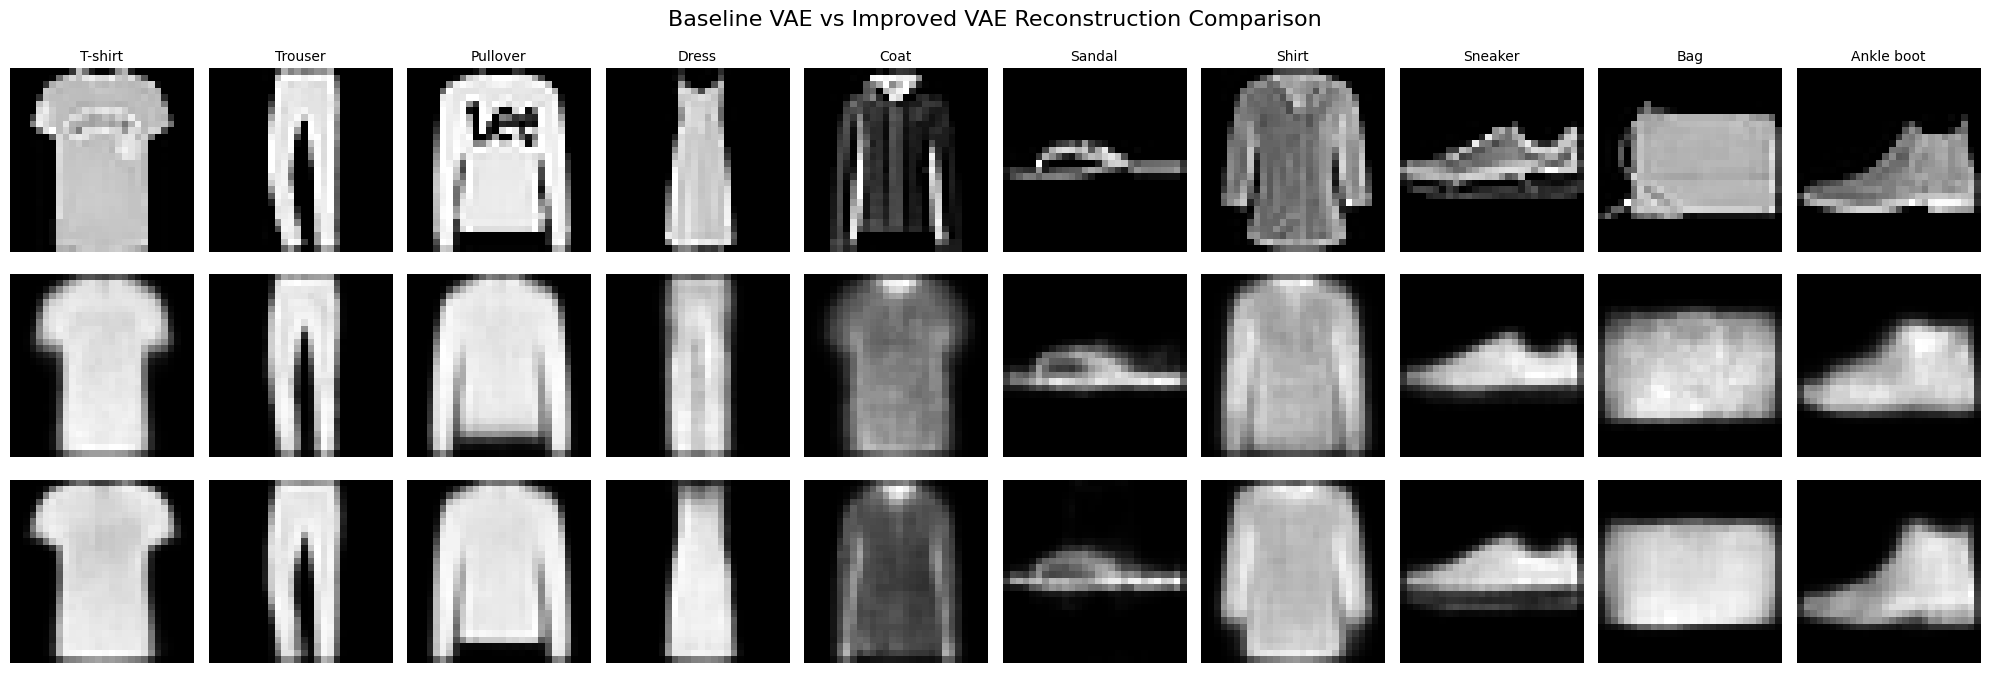

In [12]:
# Display:
# Row 1: Original images
# Row 2: Baseline VAE reconstructions
# Row 3: Improved VAE reconstructions

class_names_short = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

num_classes = 10

plt.figure(figsize=(20, 7))

for i in range(num_classes):

    # Original image
    plt.subplot(3, num_classes, i + 1)
    plt.imshow(
        comparison_images[i].reshape(28, 28),
        cmap="gray"
    )
    plt.title(class_names_short[comparison_labels[i]], fontsize=10)
    plt.axis("off")

    if i == 0:
        plt.ylabel(
            "Original",
            fontsize=12,
            rotation=0,
            labelpad=35,
            va="center"
        )

    # Baseline VAE reconstruction
    plt.subplot(3, num_classes, i + 1 + num_classes)
    plt.imshow(
        baseline_reconstructions[i].reshape(28, 28),
        cmap="gray"
    )
    plt.axis("off")

    if i == 0:
        plt.ylabel(
            "Baseline\nVAE",
            fontsize=12,
            rotation=0,
            labelpad=35,
            va="center"
        )

    # Improved VAE reconstruction
    plt.subplot(3, num_classes, i + 1 + 2 * num_classes)
    plt.imshow(
        improved_reconstructions[i].reshape(28, 28),
        cmap="gray"
    )
    plt.axis("off")

    if i == 0:
        plt.ylabel(
            "Improved\nVAE",
            fontsize=12,
            rotation=0,
            labelpad=35,
            va="center"
        )

plt.suptitle(
    "Baseline VAE vs Improved VAE Reconstruction Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Reconstruction Error on the Same Images

To support the visual comparison, reconstruction error is calculated using binary cross-entropy on the same Fashion MNIST test images.

The models use `z_mean` for deterministic reconstruction. A lower value indicates that the reconstructed pixels are closer to the original images.

This score is calculated separately from the training history, so it should be used only to compare the two models under the same evaluation method.

In [13]:
# Use the complete Fashion MNIST test set for a more stable comparison
evaluation_images = x_test_compare

# Baseline deterministic reconstruction using z_mean
baseline_eval_z_mean, _, _ = baseline_encoder.predict(
    evaluation_images,
    batch_size=128,
    verbose=0
)

baseline_eval_recon = baseline_decoder.predict(
    baseline_eval_z_mean,
    batch_size=128,
    verbose=0
)

# Improved deterministic reconstruction using z_mean
improved_eval_z_mean, _, _ = encoder.predict(
    evaluation_images,
    batch_size=128,
    verbose=0
)

improved_eval_recon = decoder.predict(
    improved_eval_z_mean,
    batch_size=128,
    verbose=0
)


def calculate_mean_reconstruction_bce(original, reconstructed):
    """Calculate mean summed binary cross-entropy per image."""

    pixel_bce = keras.losses.binary_crossentropy(
        original,
        reconstructed
    )

    image_bce = tf.reduce_sum(
        pixel_bce,
        axis=(1, 2)
    )

    return float(tf.reduce_mean(image_bce).numpy())


baseline_reconstruction_bce = calculate_mean_reconstruction_bce(
    evaluation_images,
    baseline_eval_recon
)

improved_reconstruction_bce = calculate_mean_reconstruction_bce(
    evaluation_images,
    improved_eval_recon
)

improvement_amount = (
    baseline_reconstruction_bce
    - improved_reconstruction_bce
)

improvement_percentage = (
    improvement_amount
    / baseline_reconstruction_bce
    * 100
)

print(
    f"Baseline VAE mean reconstruction BCE: "
    f"{baseline_reconstruction_bce:.4f}"
)

print(
    f"Improved VAE mean reconstruction BCE: "
    f"{improved_reconstruction_bce:.4f}"
)

print(
    f"Reduction in reconstruction BCE: "
    f"{improvement_amount:.4f}"
)

print(
    f"Percentage reduction: "
    f"{improvement_percentage:.2f}%"
)

Baseline VAE mean reconstruction BCE: 255.9446
Improved VAE mean reconstruction BCE: 238.8934
Reduction in reconstruction BCE: 17.0513
Percentage reduction: 6.66%


### Baseline vs Improved VAE Reconstruction Observation

Both VAEs preserve the general silhouette of the original Fashion MNIST items. However, the improved VAE generally produces cleaner and more structured reconstructions, particularly for upper-body clothing and bags.

Using deterministic `z_mean` reconstructions on the same 10,000 images, the baseline VAE achieved a mean reconstruction BCE of approximately **255.94**, while the improved VAE achieved approximately **238.89**.

This is a reduction of approximately **17.05 BCE units**, or **6.66%**. Therefore, the deeper architecture improved reconstruction performance while keeping the latent dimension fixed at `3`.

The visual improvement is not equally large for every image, so the following per-class analysis examines whether the improvement occurs consistently across the 10 Fashion MNIST categories.

# 9. Per-Class Reconstruction Error Comparison

The overall reconstruction loss shows the average performance of the model, but it does not show whether the model performs equally well for all 10 Fashion MNIST classes.

For this analysis, a reconstruction binary cross-entropy value is calculated separately for every image. The errors are then grouped according to the Fashion MNIST class.

Two violin plots are used:

1. A side-by-side comparison of the baseline and improved VAE reconstruction errors for each class.
2. A paired error-reduction plot showing how much the improved VAE reduced the reconstruction error for each image.

A lower reconstruction error indicates that the reconstructed image is closer to the original image. A wide violin indicates that the model's performance varies considerably within that class.

Because the existing VAE training used the combined Fashion MNIST images, this analysis should be described as a common reconstruction-set comparison rather than an unseen test-set evaluation.

### Calculate the reconstruction error for every image

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ---------------------------------------------------------
# Confirm that the required variables already exist
# ---------------------------------------------------------

required_variables = [
    "evaluation_images",
    "baseline_eval_recon",
    "improved_eval_recon",
    "y_test"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise NameError(
        "Run the earlier baseline-versus-improved reconstruction "
        "comparison cells first.\n\nMissing variables:\n"
        + "\n".join(missing_variables)
    )


# ---------------------------------------------------------
# Fashion MNIST class names
# ---------------------------------------------------------

fashion_class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


# ---------------------------------------------------------
# Validate shapes
# ---------------------------------------------------------

evaluation_images = np.asarray(
    evaluation_images,
    dtype=np.float32
)

baseline_eval_recon = np.asarray(
    baseline_eval_recon,
    dtype=np.float32
)

improved_eval_recon = np.asarray(
    improved_eval_recon,
    dtype=np.float32
)

evaluation_labels = np.asarray(
    y_test,
    dtype=np.int32
).reshape(-1)


if evaluation_images.shape != baseline_eval_recon.shape:
    raise ValueError(
        "The original images and baseline reconstructions "
        "must have the same shape."
    )

if evaluation_images.shape != improved_eval_recon.shape:
    raise ValueError(
        "The original images and improved reconstructions "
        "must have the same shape."
    )

if evaluation_images.shape[0] != evaluation_labels.shape[0]:
    raise ValueError(
        "The number of images does not match the number of labels."
    )


print("Evaluation image shape:", evaluation_images.shape)
print("Number of labels:", len(evaluation_labels))

Evaluation image shape: (10000, 28, 28, 1)
Number of labels: 10000


### Calculate per-image BCE

In [15]:
def calculate_per_image_bce(original_images, reconstructed_images):
    """
    Calculate summed binary cross-entropy separately for every image.

    Returns
    -------
    numpy.ndarray
        One reconstruction-error value per image.
    """

    original_tensor = tf.convert_to_tensor(
        original_images,
        dtype=tf.float32
    )

    reconstructed_tensor = tf.convert_to_tensor(
        reconstructed_images,
        dtype=tf.float32
    )

    epsilon = tf.keras.backend.epsilon()

    reconstructed_tensor = tf.clip_by_value(
        reconstructed_tensor,
        epsilon,
        1.0 - epsilon
    )

    pixel_bce = -(
        original_tensor * tf.math.log(reconstructed_tensor)
        + (1.0 - original_tensor)
        * tf.math.log(1.0 - reconstructed_tensor)
    )

    image_bce = tf.reduce_sum(
        pixel_bce,
        axis=(1, 2, 3)
    )

    return image_bce.numpy()


baseline_error_per_image = calculate_per_image_bce(
    evaluation_images,
    baseline_eval_recon
)

improved_error_per_image = calculate_per_image_bce(
    evaluation_images,
    improved_eval_recon
)

# Positive value means the improved VAE produced a lower error.
error_reduction_per_image = (
    baseline_error_per_image
    - improved_error_per_image
)


print(
    "Baseline mean BCE:",
    round(float(np.mean(baseline_error_per_image)), 4)
)

print(
    "Improved mean BCE:",
    round(float(np.mean(improved_error_per_image)), 4)
)

print(
    "Mean BCE reduction:",
    round(float(np.mean(error_reduction_per_image)), 4)
)

print(
    "Percentage of images improved:",
    round(
        float(np.mean(error_reduction_per_image > 0) * 100),
        2
    ),
    "%"
)

Baseline mean BCE: 255.9453
Improved mean BCE: 238.8936
Mean BCE reduction: 17.0517
Percentage of images improved: 94.62 %


### per-class summary table

In [16]:
class_summary_rows = []

for class_id, class_name in enumerate(fashion_class_names):

    class_mask = evaluation_labels == class_id

    baseline_class_errors = baseline_error_per_image[class_mask]
    improved_class_errors = improved_error_per_image[class_mask]

    # Paired reduction for the same images
    class_error_reduction = (
        baseline_class_errors
        - improved_class_errors
    )

    baseline_mean = float(
        np.mean(baseline_class_errors)
    )

    improved_mean = float(
        np.mean(improved_class_errors)
    )

    baseline_median = float(
        np.median(baseline_class_errors)
    )

    improved_median = float(
        np.median(improved_class_errors)
    )

    # Correct paired improvement statistics
    mean_reduction = float(
        np.mean(class_error_reduction)
    )

    median_reduction = float(
        np.median(class_error_reduction)
    )

    median_reduction_percentage = (
        median_reduction
        / baseline_median
        * 100
        if baseline_median != 0
        else np.nan
    )

    images_improved_percentage = float(
        np.mean(class_error_reduction > 0)
        * 100
    )

    class_summary_rows.append(
        {
            "Class ID": class_id,
            "Fashion MNIST Class": class_name,
            "Number of Images": int(np.sum(class_mask)),
            "Baseline Mean BCE": baseline_mean,
            "Improved Mean BCE": improved_mean,
            "Baseline Median BCE": baseline_median,
            "Improved Median BCE": improved_median,
            "Mean BCE Reduction": mean_reduction,
            "Median BCE Reduction": median_reduction,
            "Median Reduction (%)": median_reduction_percentage,
            "Images Improved (%)": images_improved_percentage
        }
    )


class_error_summary = pd.DataFrame(
    class_summary_rows
)

display(
    class_error_summary.round(3)
)

,Class ID,Fashion MNIST Class,Number of Images,Baseline Mean BCE,Improved Mean BCE,Baseline Median BCE,Improved Median BCE,Mean BCE Reduction,Median BCE Reduction,Median Reduction (%),Images Improved (%)
0,0,T-shirt/top,1000,293.871,274.959,292.896,277.161,18.912,14.065,4.802,95.0
1,1,Trouser,1000,178.143,164.150,166.739,156.210,13.993,9.368,5.619,90.5
2,2,Pullover,1000,320.901,304.386,323.077,308.028,16.515,12.209,3.779,96.6
3,3,Dress,1000,223.877,205.863,214.639,198.879,18.014,13.870,6.462,94.4
4,4,Coat,1000,293.755,276.199,294.375,276.351,17.556,12.096,4.109,96.6
5,5,Sandal,1000,194.430,182.158,188.527,178.942,12.272,8.820,4.678,92.0
6,6,Shirt,1000,317.237,299.466,315.495,302.362,17.771,9.343,2.961,95.4
7,7,Sneaker,1000,171.955,162.665,167.461,159.969,9.290,7.443,4.444,95.2
8,8,Bag,1000,322.726,294.705,315.297,293.038,28.021,16.856,5.346,93.3
9,9,Ankle boot,1000,242.558,224.386,235.999,220.521,18.173,13.725,5.816,97.2


### side-by-side violin plot

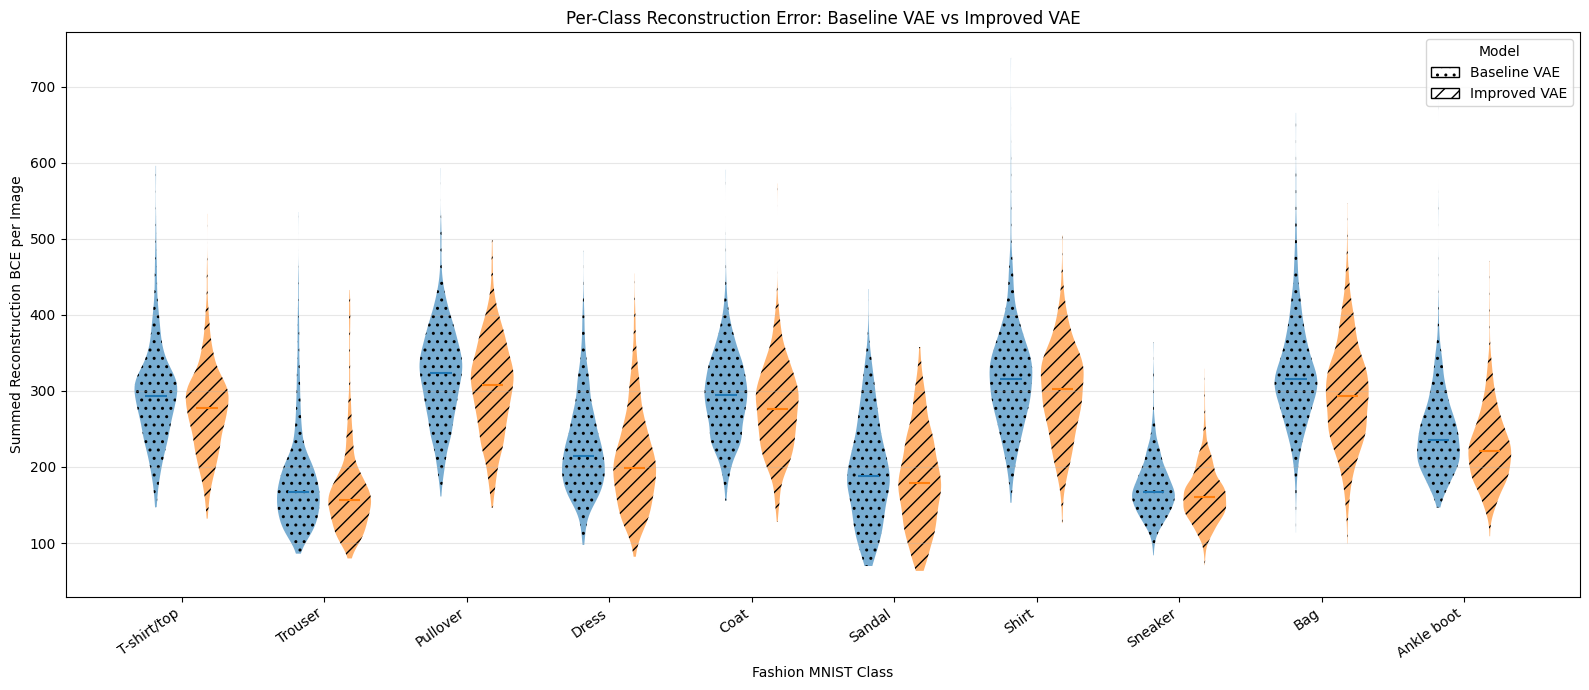

In [17]:
from matplotlib.patches import Patch


baseline_class_distributions = []
improved_class_distributions = []

for class_id in range(10):

    class_mask = evaluation_labels == class_id

    baseline_class_distributions.append(
        baseline_error_per_image[class_mask]
    )

    improved_class_distributions.append(
        improved_error_per_image[class_mask]
    )


class_positions = np.arange(10)
position_offset = 0.18
violin_width = 0.30


fig, ax = plt.subplots(
    figsize=(16, 7)
)


baseline_violins = ax.violinplot(
    baseline_class_distributions,
    positions=class_positions - position_offset,
    widths=violin_width,
    showmeans=False,
    showmedians=True,
    showextrema=False
)

improved_violins = ax.violinplot(
    improved_class_distributions,
    positions=class_positions + position_offset,
    widths=violin_width,
    showmeans=False,
    showmedians=True,
    showextrema=False
)


# Use different hatch patterns so the models remain distinguishable.
for body in baseline_violins["bodies"]:
    body.set_alpha(0.60)
    body.set_hatch("..")

for body in improved_violins["bodies"]:
    body.set_alpha(0.60)
    body.set_hatch("//")


ax.set_xticks(class_positions)

ax.set_xticklabels(
    fashion_class_names,
    rotation=35,
    ha="right"
)

ax.set_xlabel(
    "Fashion MNIST Class"
)

ax.set_ylabel(
    "Summed Reconstruction BCE per Image"
)

ax.set_title(
    "Per-Class Reconstruction Error: "
    "Baseline VAE vs Improved VAE"
)

ax.grid(
    axis="y",
    alpha=0.3
)


legend_items = [
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch="..",
        label="Baseline VAE"
    ),
    Patch(
        facecolor="white",
        edgecolor="black",
        hatch="//",
        label="Improved VAE"
    )
]

ax.legend(
    handles=legend_items,
    title="Model"
)

plt.tight_layout()
plt.show()

### Per-Class Reconstruction Error Distribution Observation

The improved VAE shows a downward shift in reconstruction error for all 10 Fashion MNIST classes compared with the baseline VAE. This indicates that the improved architecture provides a general improvement across the dataset rather than improving only a small number of categories.

The amount of improvement differs between classes. **Bag** shows the largest median reduction in reconstruction error, while **Sneaker** shows the smallest median reduction. However, the improved Sneaker distribution is still generally lower than the baseline distribution.

Under the improved VAE, **Trouser** has the lowest typical reconstruction error, suggesting that its simple and distinctive silhouette is easier for the model to reconstruct. In contrast, **Pullover** has the highest typical reconstruction error, indicating that it remains one of the most difficult classes. This is likely related to its visual similarity with other upper-body categories such as T-shirt/top, Coat and Shirt.

Classes such as **Shirt** and **Bag** also have relatively wide violin distributions and long upper tails. This shows that reconstruction difficulty varies considerably between images within the same class. Some examples are reconstructed well, while more unusual shapes, poses or pixel patterns produce much higher errors.

Although the baseline and improved distributions still overlap, the central regions of the improved violins are consistently lower. Therefore, the chart supports the conclusion that the improved VAE reduces reconstruction error across every Fashion MNIST class, while class complexity and within-class variation continue to affect reconstruction performance.

# 10. Per-Class Reconstruction Error Reduction

The error-reduction value is calculated as:

`baseline reconstruction error − improved reconstruction error`

A positive value means that the improved VAE reconstructed the image more accurately. A negative value means that the baseline VAE performed better for that image.

The horizontal line at 0 represents no difference between the two models.

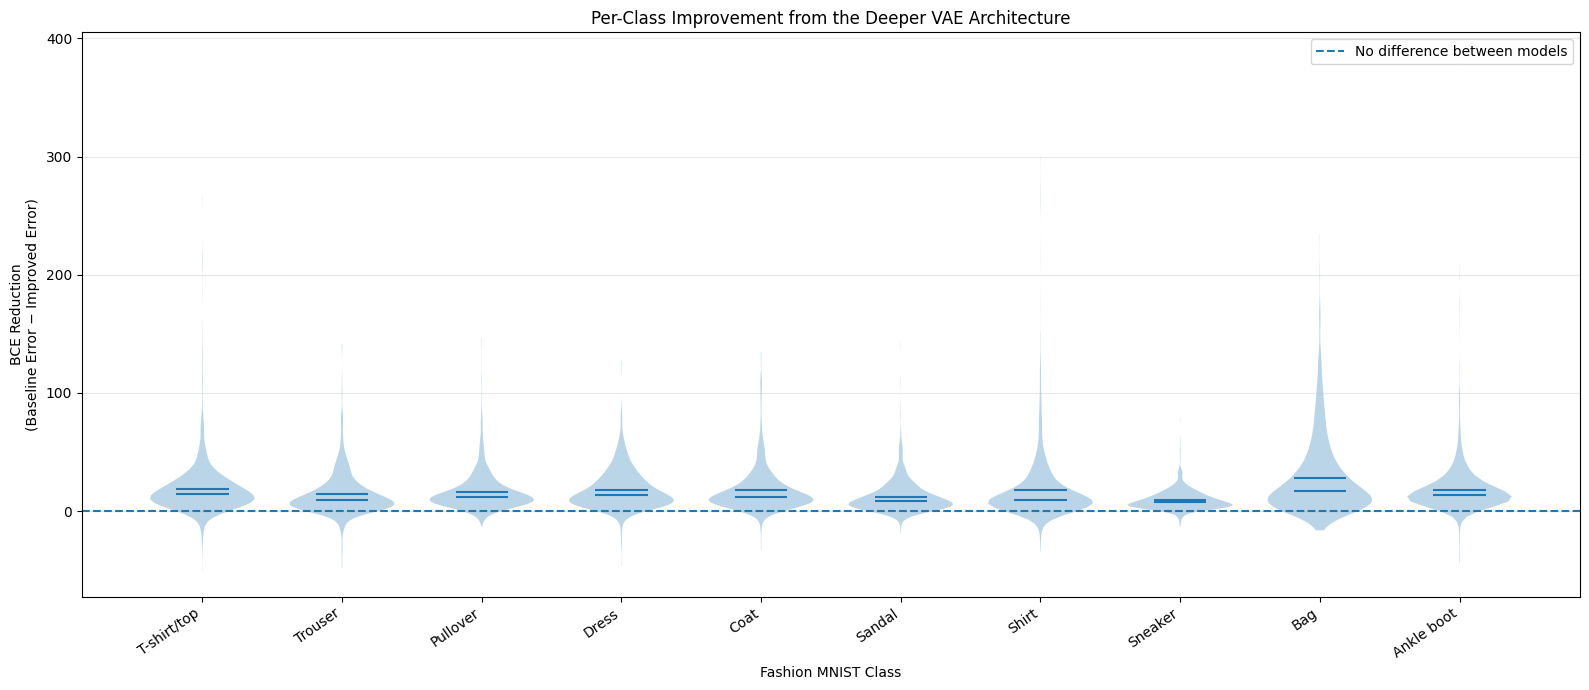

In [18]:
class_reduction_distributions = []

for class_id in range(10):

    class_mask = evaluation_labels == class_id

    class_reduction_distributions.append(
        error_reduction_per_image[class_mask]
    )


plt.figure(
    figsize=(16, 7)
)

plt.violinplot(
    class_reduction_distributions,
    positions=np.arange(10),
    widths=0.75,
    showmeans=True,
    showmedians=True,
    showextrema=False
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1.5,
    label="No difference between models"
)

plt.xticks(
    ticks=np.arange(10),
    labels=fashion_class_names,
    rotation=35,
    ha="right"
)

plt.xlabel(
    "Fashion MNIST Class"
)

plt.ylabel(
    "BCE Reduction\n"
    "(Baseline Error − Improved Error)"
)

plt.title(
    "Per-Class Improvement from the Deeper VAE Architecture"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend()

plt.tight_layout()
plt.show()

### Paired Per-Class Reconstruction Improvement Observation

This chart measures the reconstruction-error reduction for each individual image:

**BCE Reduction = Baseline Error − Improved Error**

Therefore:

- values above `0` indicate that the improved VAE reconstructed the image more accurately;
- values below `0` indicate that the baseline VAE performed better for that particular image;
- the dashed horizontal line represents no difference between the two models.

The central regions and median lines for all 10 classes are above zero. This shows that the deeper VAE architecture produced a positive typical improvement for every Fashion MNIST category.

**Bag** shows the largest median reconstruction-error reduction, at approximately **16.86 BCE units**. It also has one of the widest distributions and a long positive upper tail, indicating that some Bag images benefited substantially more than others from the deeper architecture.

**Sneaker** shows the smallest median reduction, at approximately **7.44 BCE units**. This suggests that the baseline model was already comparatively effective at reconstructing many Sneaker images, leaving less room for improvement.

Several classes, particularly **Bag**, **Shirt**, **T-shirt/top**, and **Ankle boot**, have long positive tails. This means that although their typical improvements are moderate, some individual images achieve very large reconstruction-error reductions.

A small portion of each violin extends below zero. Therefore, the improved VAE does not outperform the baseline for every individual image. However, these negative cases form a relatively small part of the distributions, and approximately **94.62%** of all evaluated images had lower reconstruction error under the improved VAE.

Overall, the paired comparison provides stronger evidence than comparing the two model distributions separately because it directly measures how much each individual image improved. The results show that the deeper architecture produces a broad and consistent reconstruction benefit across all 10 Fashion MNIST classes, although the size of the improvement varies by class and by image.

### Automatically identify the important classes

In [19]:
most_improved_class = class_error_summary.loc[
    class_error_summary[
        "Median BCE Reduction"
    ].idxmax()
]

least_improved_class = class_error_summary.loc[
    class_error_summary[
        "Median BCE Reduction"
    ].idxmin()
]

easiest_improved_class = class_error_summary.loc[
    class_error_summary[
        "Improved Median BCE"
    ].idxmin()
]

hardest_improved_class = class_error_summary.loc[
    class_error_summary[
        "Improved Median BCE"
    ].idxmax()
]

most_consistently_improved_class = class_error_summary.loc[
    class_error_summary[
        "Images Improved (%)"
    ].idxmax()
]


print(
    "Largest median improvement:",
    most_improved_class["Fashion MNIST Class"],
    "| BCE reduction:",
    round(
        most_improved_class["Median BCE Reduction"],
        3
    )
)

print(
    "Smallest median improvement:",
    least_improved_class["Fashion MNIST Class"],
    "| BCE reduction:",
    round(
        least_improved_class["Median BCE Reduction"],
        3
    )
)

print(
    "Lowest improved-VAE median error:",
    easiest_improved_class["Fashion MNIST Class"],
    "| Median BCE:",
    round(
        easiest_improved_class["Improved Median BCE"],
        3
    )
)

print(
    "Highest improved-VAE median error:",
    hardest_improved_class["Fashion MNIST Class"],
    "| Median BCE:",
    round(
        hardest_improved_class["Improved Median BCE"],
        3
    )
)

print(
    "Highest percentage of images improved:",
    most_consistently_improved_class[
        "Fashion MNIST Class"
    ],
    "|",
    round(
        most_consistently_improved_class[
            "Images Improved (%)"
        ],
        2
    ),
    "%"
)

Largest median improvement: Bag | BCE reduction: 16.856
Smallest median improvement: Sneaker | BCE reduction: 7.443
Lowest improved-VAE median error: Trouser | Median BCE: 156.21
Highest improved-VAE median error: Pullover | Median BCE: 308.028
Highest percentage of images improved: Ankle boot | 97.2 %


### Per-Class Reconstruction Error Observation

The improved VAE produced a lower reconstruction-error distribution than the baseline VAE across all 10 Fashion MNIST classes.

Overall, approximately **94.62%** of the 10,000 evaluated images had a lower reconstruction error under the improved model.

**Bag** showed the largest median BCE reduction, at approximately **16.86**. **Sneaker** showed the smallest median reduction, at approximately **7.44**, although most sneaker images still improved.

Under the improved VAE, **Trouser** had the lowest median reconstruction error at approximately **156.21**, making it the easiest class to reconstruct. **Pullover** had the highest median reconstruction error at approximately **308.03**, making it the most difficult class under this evaluation.

**Ankle boot** had the highest percentage of individually improved images, at approximately **97.2%**.

The wider violin distributions for classes such as Pullover, Shirt, and Bag show that reconstruction difficulty varies substantially among images within those categories. This provides more detail than the overall reconstruction loss because it shows both class-level performance and variation within each class.

# 11. Generate Images using Improved VAE

The generated grid below uses the improved VAE architecture with `latent_dim = 3`.

The scale value is set to `2.0` because the previous experiment showed that `scale = 2.0` gave the best balance between image variety and image quality.

Since `latent_dim = 3`, the grid varies `z[0]` and `z[1]`, while `z[2]` is frozen at 0. Therefore, the grid shows a 2D slice of the full 3D latent space.

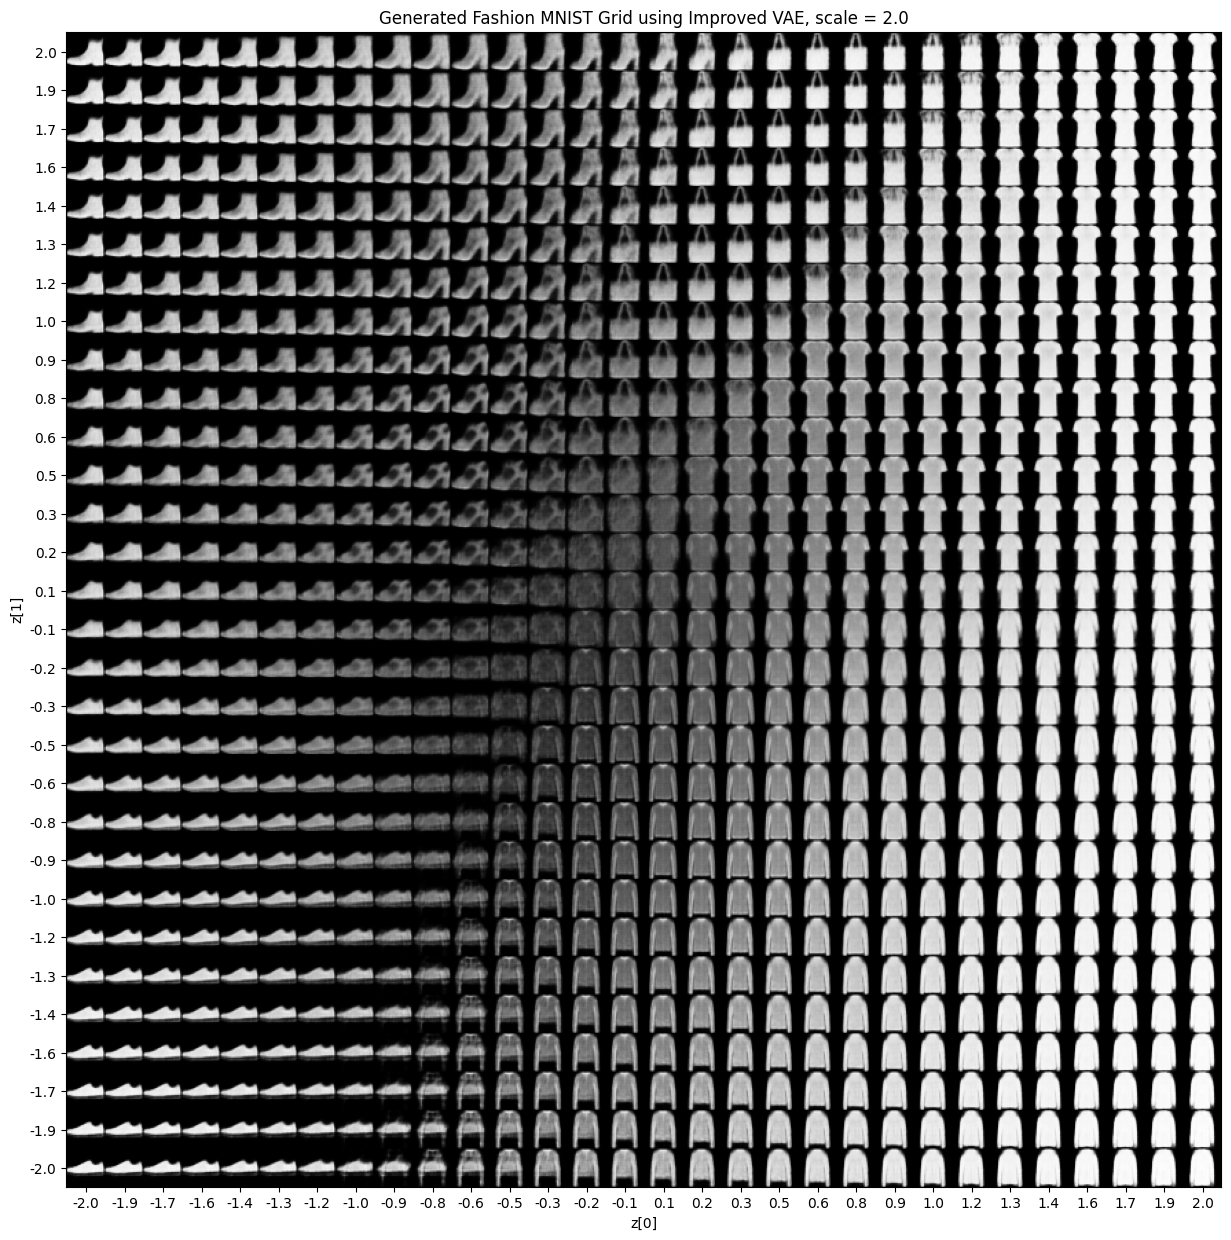

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def plot_latent_space(vae, n=30, figsize=15, scale=1.0):
    # Size of each Fashion MNIST image
    digit_size = 28

    # Create an empty canvas to store all generated images
    figure = np.zeros((digit_size * n, digit_size * n))

    # Get decoder latent dimension automatically
    latent_dim = vae.decoder.input_shape[-1]

    # Create values for z[0] and z[1]
    grid_x = np.linspace(-scale, scale, n)
    grid_y = np.linspace(-scale, scale, n)[::-1]

    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            # Create latent vector with correct number of inputs
            # For latent_dim > 2, the extra latent values are kept as 0
            z_sample = np.zeros((1, latent_dim))
            z_sample[0, 0] = xi

            if latent_dim > 1:
                z_sample[0, 1] = yi

            # Generate image using decoder
            x_decoded = vae.decoder.predict(z_sample, verbose=0)
            digit = x_decoded[0].reshape(digit_size, digit_size)

            # Place generated image into the grid
            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = digit

    # Plot the full image grid
    plt.figure(figsize=(figsize, figsize))

    start_range = digit_size // 2
    end_range = n * digit_size + start_range
    pixel_range = np.arange(start_range, end_range, digit_size)

    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)

    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.title(f"Generated Fashion MNIST Grid using Improved VAE, scale = {scale}")
    plt.imshow(figure, cmap="Greys_r")
    plt.show()

plot_latent_space(vae, scale=2.0)

### Generated Grid Observation

The improved VAE produces a continuous transition between different Fashion MNIST-like shapes across the latent grid.

As `z[0]` changes from negative to positive values, the generated images generally transition from footwear-like shapes towards trousers and upper-body clothing. Changes in `z[1]` alter the shape, length, and class-like appearance of the outputs.

The grid contains recognisable footwear, trousers, dresses, shirts, and other upper-body silhouettes. However, some neighbouring images remain similar because the latent space is continuous rather than divided into fixed class regions.

Since `z[2]` is fixed at 0, this grid represents only one 2D slice of the full 3D latent space. The later pairwise and frozen-dimension experiments examine the information not visible in this grid.

In [21]:
fashion_class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

# 12. Visualise Label Clusters

The label cluster plot shows how the improved encoder maps Fashion MNIST images into the latent space. Since the model uses `latent_dim = 3`, this plot visualises the first two dimensions, `z[0]` and `z[1]`.

The plot uses `z_mean` instead of the sampled latent vector `z` because `z_mean` gives a more stable representation of each image.

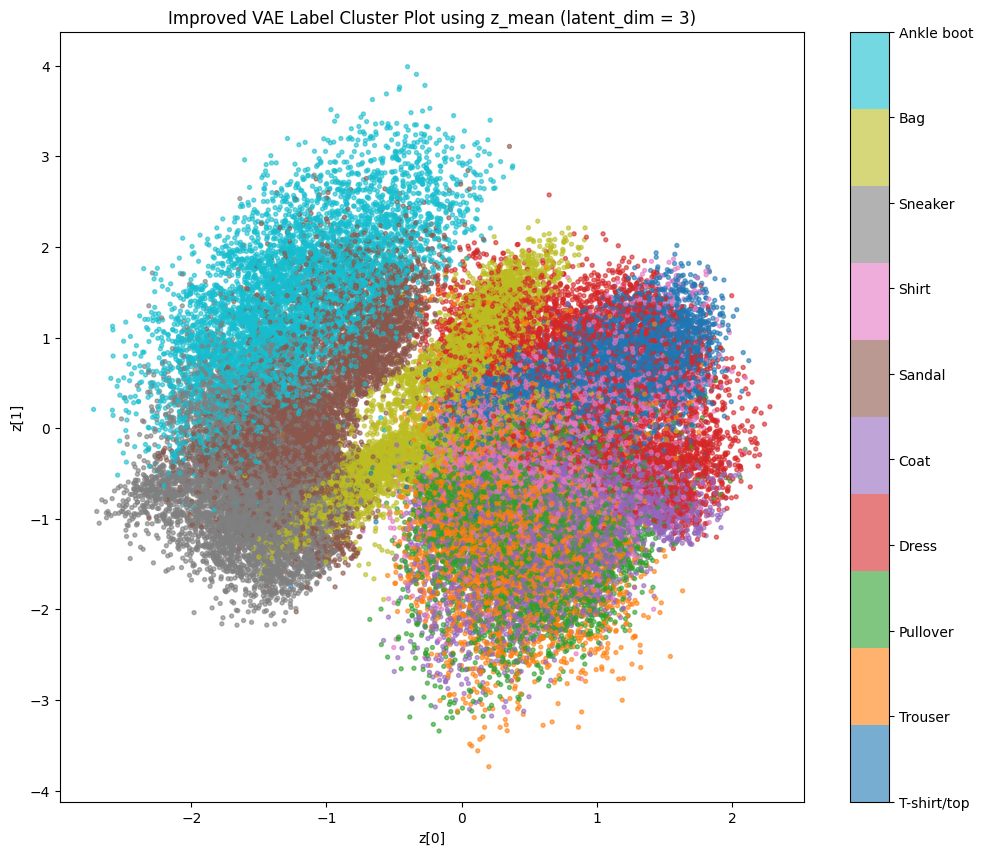

In [22]:
def plot_label_clusters(vae, data, labels):
    # Use z_mean because it gives a stable latent representation
    z_mean, _, _ = vae.encoder.predict(data, verbose=0)

    plt.figure(figsize=(12, 10))

    scatter = plt.scatter(
        z_mean[:, 0],
        z_mean[:, 1],
        c=labels,
        cmap="tab10",
        s=8,
        alpha=0.6
    )

    cbar = plt.colorbar(scatter, ticks=range(10))
    cbar.ax.set_yticklabels([fashion_class_names[i] for i in range(10)])

    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.title("Improved VAE Label Cluster Plot using z_mean (latent_dim = 3)")
    plt.show()


(x_train, y_train), _ = keras.datasets.fashion_mnist.load_data()
x_train = np.expand_dims(x_train, -1).astype("float32") / 255

plot_label_clusters(vae, x_train, y_train)

### Label Cluster Observation

The direct `z[0]`–`z[1]` plot shows clear class-related organisation in the improved latent space.

Footwear classes occupy relatively distinctive regions on the left side of the plot, while Trouser forms a more recognisable region towards the lower-right area. Ankle boot also occupies a broad and relatively distinctive upper-left region.

Upper-body categories such as T-shirt/top, Pullover, Dress, Coat, and Shirt overlap substantially in the central and right-side regions. This is expected because these classes share similar silhouettes.

The plot therefore shows that the improved encoder learned meaningful class structure, although the first two dimensions alone do not completely separate all 10 categories.

# 13. Pairwise Latent Space Projections

Since the improved VAE uses `latent_dim = 3`, plotting only `z[0]` against `z[1]` may not show the full latent structure.

To better analyse the 3D latent space, three pairwise projections are shown:

- `z[0]` vs `z[1]`
- `z[0]` vs `z[2]`
- `z[1]` vs `z[2]`

This helps check whether class information is stored in the third latent dimension.

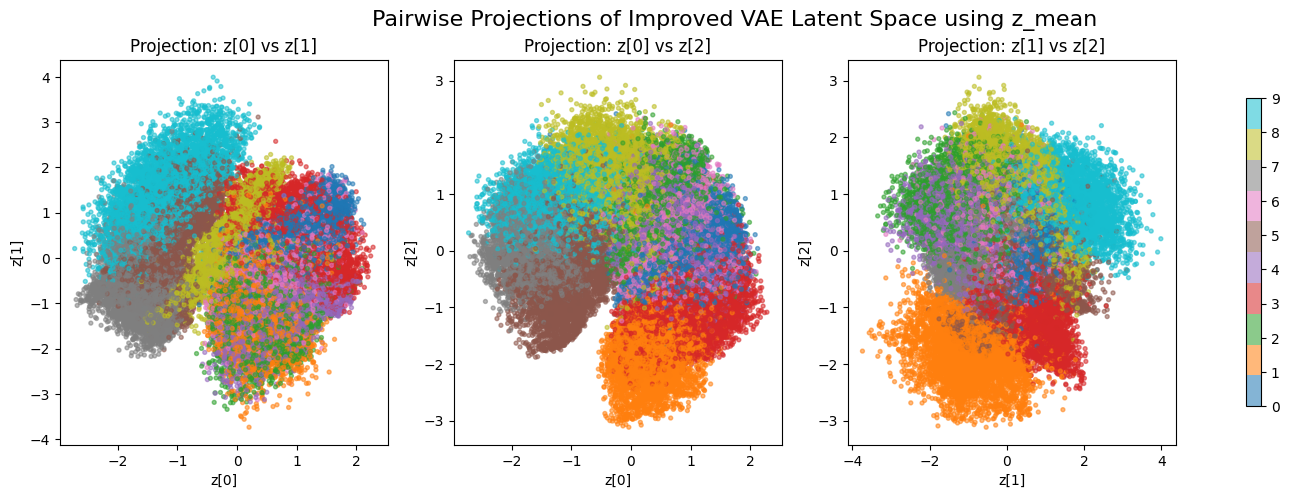

In [23]:
# Pairwise latent space projections for improved VAE

(x_train_plot, y_train_plot), _ = keras.datasets.fashion_mnist.load_data()
x_train_plot = np.expand_dims(x_train_plot, -1).astype("float32") / 255

z_mean_plot, _, _ = vae.encoder.predict(x_train_plot, verbose=0)

projection_pairs = [(0, 1), (0, 2), (1, 2)]

plt.figure(figsize=(18, 5))

for i, (dim1, dim2) in enumerate(projection_pairs):
    plt.subplot(1, 3, i + 1)

    scatter = plt.scatter(
        z_mean_plot[:, dim1],
        z_mean_plot[:, dim2],
        c=y_train_plot,
        cmap="tab10",
        s=8,
        alpha=0.55
    )

    plt.xlabel(f"z[{dim1}]")
    plt.ylabel(f"z[{dim2}]")
    plt.title(f"Projection: z[{dim1}] vs z[{dim2}]")

plt.colorbar(scatter, ax=plt.gcf().axes, ticks=range(10), shrink=0.8)
plt.suptitle("Pairwise Projections of Improved VAE Latent Space using z_mean", fontsize=16)
plt.show()

### Pairwise Projection Observation

All three pairwise projections show substantial spread, confirming that the improved model uses `z[0]`, `z[1]`, and `z[2]`.

The `z[0]`–`z[1]` projection separates footwear, trousers, and several upper-body regions. The projections involving `z[2]` also show meaningful class-related structure, demonstrating that the third dimension contributes additional information rather than remaining inactive.

Upper-body categories such as T-shirt/top, Pullover, Coat, and Shirt continue to overlap across the different projections because their visual features are similar.

This is an improvement over the earlier baseline `latent_dim = 3` model, where `z[2]` became almost inactive after full training.

# 14. t-SNE Cluster Plot using z_mean

t-SNE is used to reduce the full 3-dimensional `z_mean` vectors into two dimensions for visualisation.

This gives another view of how the improved VAE groups Fashion MNIST classes in the latent space.

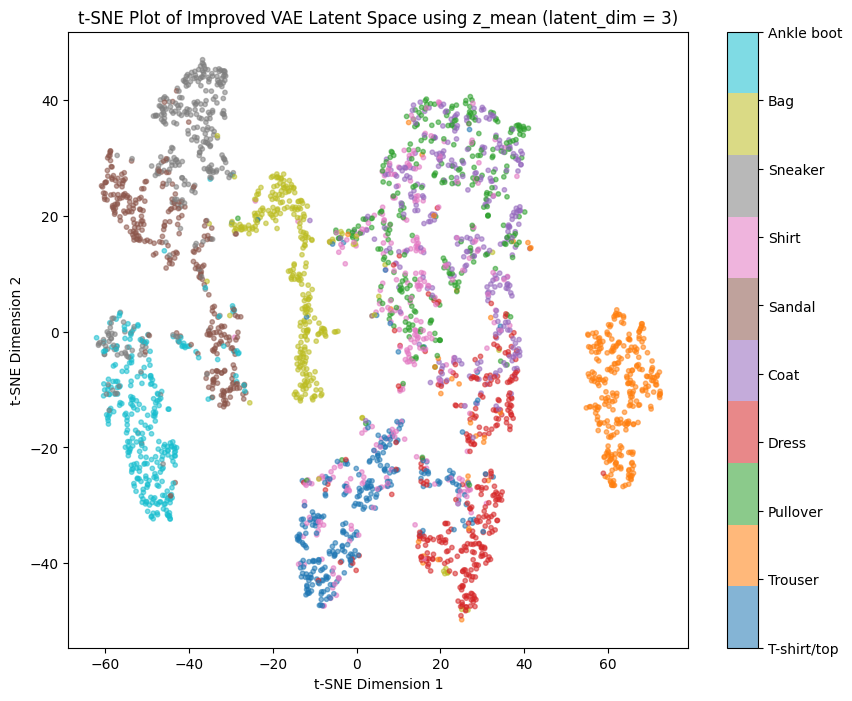

In [24]:
from sklearn.manifold import TSNE

num_samples = 3000

x_subset = x_train_plot[:num_samples]
y_subset = y_train_plot[:num_samples]

z_mean_subset, _, _ = vae.encoder.predict(x_subset, verbose=0)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

z_tsne = tsne.fit_transform(z_mean_subset)

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    z_tsne[:, 0],
    z_tsne[:, 1],
    c=y_subset,
    cmap="tab10",
    s=10,
    alpha=0.55
)

cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels([fashion_class_names[i] for i in range(10)])

plt.title("t-SNE Plot of Improved VAE Latent Space using z_mean (latent_dim = 3)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.show()

### t-SNE Observation

The t-SNE plot forms several clear local groups in the improved latent representation.

Trouser, footwear, and Bag-related samples form relatively distinctive regions, while T-shirt/top, Pullover, Dress, Coat, and Shirt remain more strongly mixed.

This is consistent with the direct and pairwise latent-space plots: categories with distinctive silhouettes are easier to organise, while similar upper-body clothing categories share overlapping representations.

The t-SNE result supports the conclusion that the improved encoder learned meaningful class structure. However, t-SNE emphasises local neighbourhoods and can distort global distances, so it should be interpreted together with the original pairwise `z_mean` plots.

# 15. Class-Wise Latent Distribution using z_mean

The t-SNE and pairwise scatter plots show how Fashion MNIST classes are positioned in the latent space. To examine the class distributions more closely, violin plots are used to show how each class is distributed along `z[0]`, `z[1]`, and `z[2]`.

Each plot represents one latent dimension. A large difference between class distributions suggests that the dimension helps separate those classes. Strongly overlapping distributions suggest that the classes share similar latent features.

The plots use `z_mean` because it gives a stable latent representation without the random noise introduced during sampling.

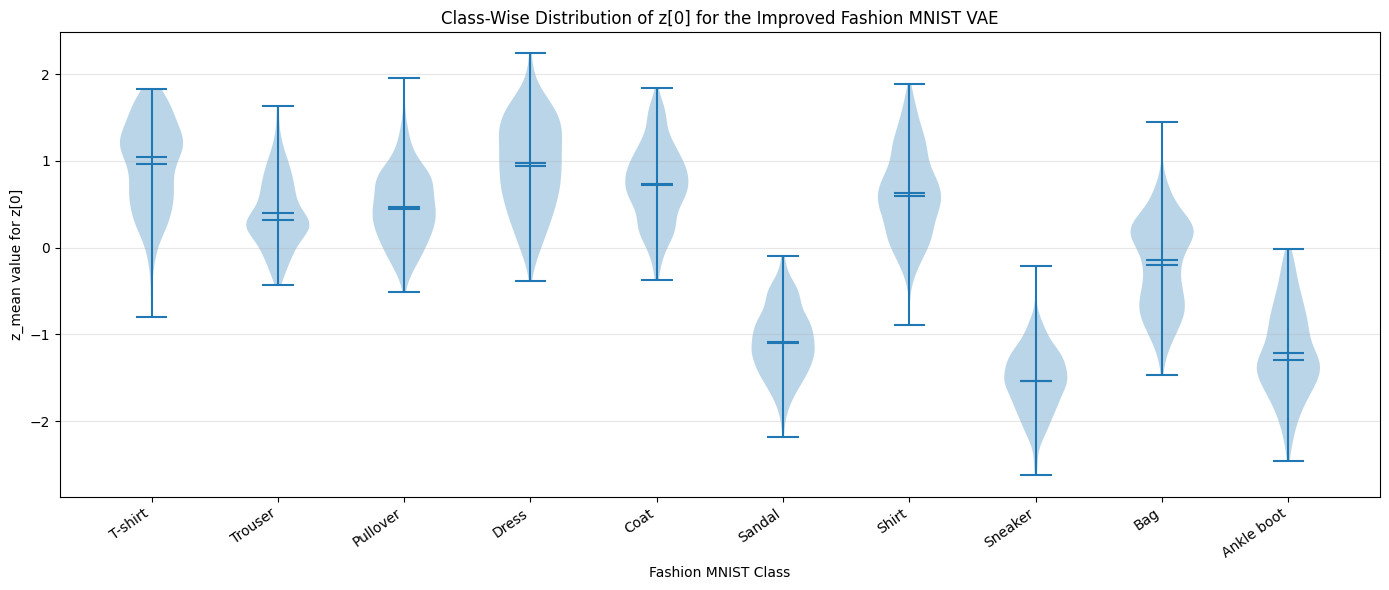

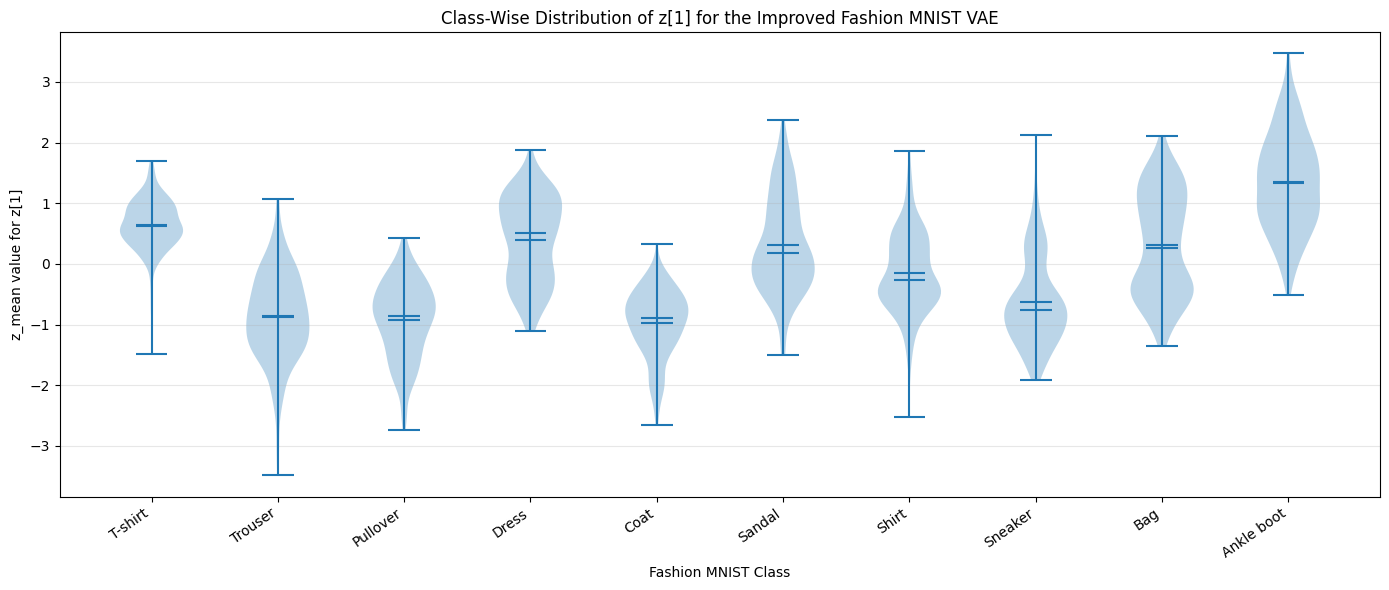

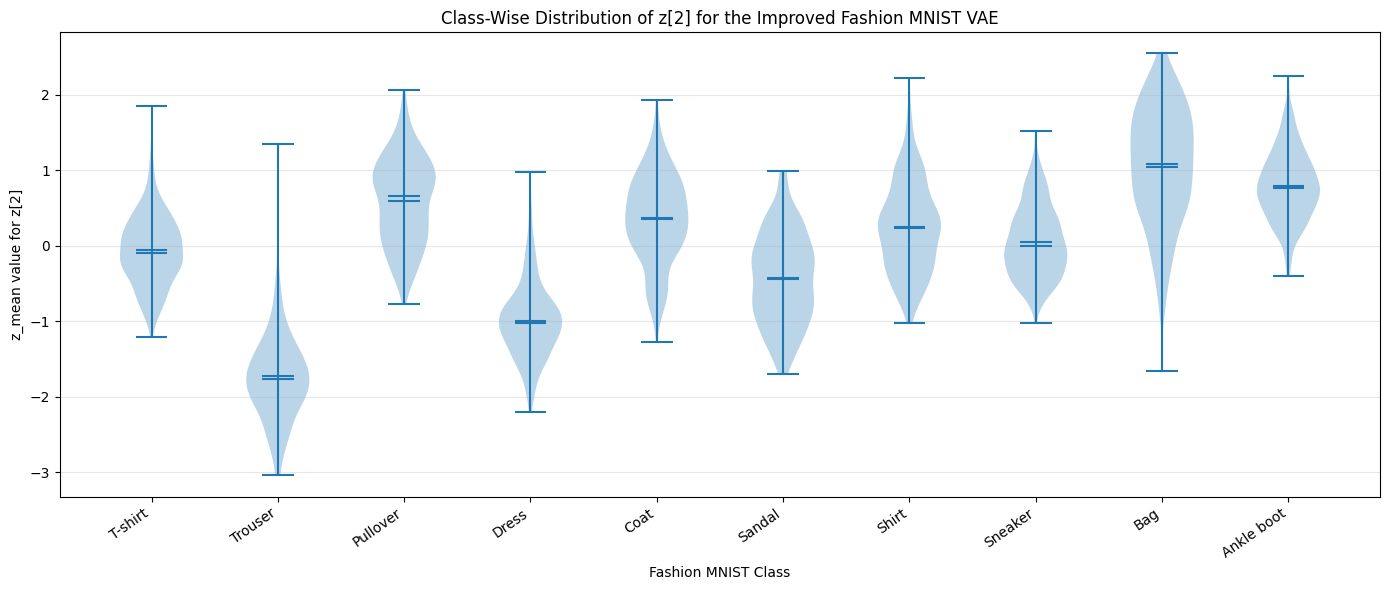

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Use the same subset already prepared for the t-SNE analysis
# z_mean_subset shape: (number_of_samples, 3)
# y_subset contains the corresponding Fashion MNIST labels

class_names_short = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

for latent_index in range(z_mean_subset.shape[1]):

    class_distributions = [
        z_mean_subset[y_subset == class_id, latent_index]
        for class_id in range(10)
    ]

    plt.figure(figsize=(14, 6))

    plt.violinplot(
        class_distributions,
        showmeans=True,
        showmedians=True
    )

    plt.xticks(
        ticks=np.arange(1, 11),
        labels=class_names_short,
        rotation=35,
        ha="right"
    )

    plt.xlabel("Fashion MNIST Class")
    plt.ylabel(f"z_mean value for z[{latent_index}]")
    plt.title(
        f"Class-Wise Distribution of z[{latent_index}] "
        "for the Improved Fashion MNIST VAE"
    )

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### Class-Wise Violin Plot Observation

The class-wise violin plots show that each latent dimension contributes differently to the representation of Fashion MNIST classes.

For `z[0]`, footwear categories such as Sandal, Sneaker, and Ankle boot are generally positioned at more negative values, while many upper-body categories, Dress, and Trouser occupy more positive values. This suggests that `z[0]` helps separate footwear from clothing worn on the upper or lower body.

For `z[1]`, Ankle boot is generally positioned more positively, while Trouser, Pullover, Coat, and Sneaker tend to occupy more negative values. However, several classes still overlap.

For `z[2]`, Trouser and Dress are mainly positioned at negative values, while Pullover, Coat, Bag, and Ankle boot tend to occupy more positive values.

These patterns show that the latent dimensions do not correspond to single class labels. Instead, each dimension appears to represent combinations of visual features such as item type, shape, length, and silhouette.

# 16. Violin Plot of Improved VAE Latent Dimensions

A violin plot is used to check how the three latent dimensions are distributed.

Since the VAE uses KL loss, the latent values are expected to be mostly centred around 0. The important part is the spread of each latent dimension. A wider spread suggests that the dimension is being used to capture variation in the images.

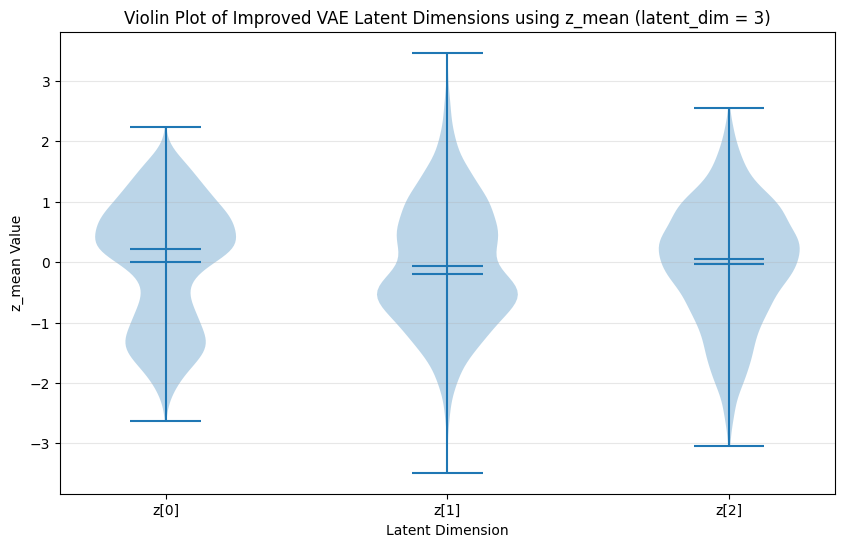

In [26]:
plt.figure(figsize=(10, 6))

data_to_plot = [z_mean_subset[:, i] for i in range(z_mean_subset.shape[1])]

plt.violinplot(
    data_to_plot,
    showmeans=True,
    showmedians=True
)

plt.xticks(
    ticks=np.arange(1, z_mean_subset.shape[1] + 1),
    labels=[f"z[{i}]" for i in range(z_mean_subset.shape[1])]
)

plt.title("Violin Plot of Improved VAE Latent Dimensions using z_mean (latent_dim = 3)")
plt.xlabel("Latent Dimension")
plt.ylabel("z_mean Value")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [27]:
for i in range(z_mean_subset.shape[1]):
    print(
        f"z[{i}] mean: {z_mean_subset[:, i].mean():.4f}, "
        f"std: {z_mean_subset[:, i].std():.4f}, "
        f"min: {z_mean_subset[:, i].min():.4f}, "
        f"max: {z_mean_subset[:, i].max():.4f}"
    )

z[0] mean: 0.0049, std: 1.0189, min: -2.6271, max: 2.2401
z[1] mean: -0.0689, std: 1.0174, min: -3.4874, max: 3.4684
z[2] mean: -0.0348, std: 0.9951, min: -3.0402, max: 2.5506


### Violin Plot Observation

All three improved-VAE latent dimensions are centred close to 0 and show substantial spread.

The measured statistics are:

- `z[0]`: mean approximately **0.0049**, standard deviation approximately **1.0189**
- `z[1]`: mean approximately **−0.0689**, standard deviation approximately **1.0174**
- `z[2]`: mean approximately **−0.0348**, standard deviation approximately **0.9951**

The means being close to 0 and the standard deviations being close to 1 are consistent with the KL-loss regularisation towards a standard normal distribution.

Most importantly, all three dimensions are actively used. This is a clear improvement over the earlier baseline model, where the third dimension had a standard deviation of only approximately `0.0041`.

# 17. Latent Dimension Variation Matrix

The normal generated image grid only varies `z[0]` and `z[1]`. Since the improved VAE uses `latent_dim = 3`, the third dimension `z[2]` is frozen at 0 in the normal grid.

To better understand the role of each latent dimension, this matrix varies one latent dimension at a time while keeping the other dimensions frozen at 0.

The tested values are centred around 0, such as `-2.0`, `-1.5`, `-1.0`, `0.0`, `1.0`, `1.5`, and `2.0`. This is suitable because the VAE uses KL loss to regularise the latent space around 0.

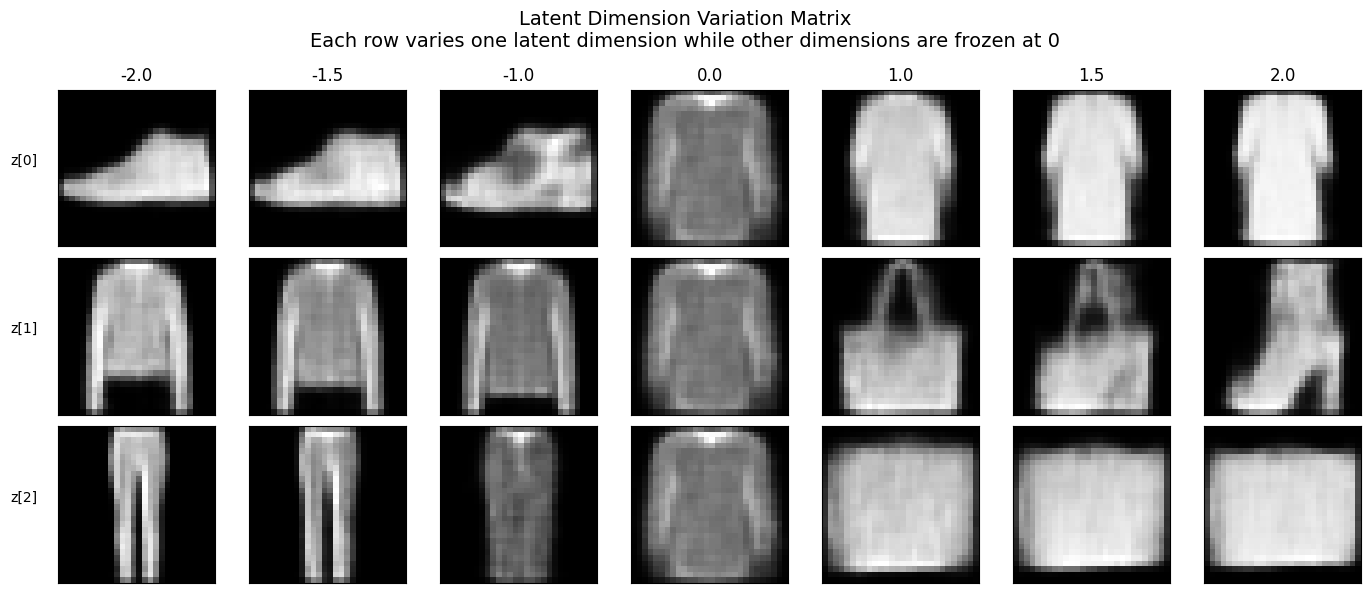

In [28]:
# Latent Dimension Variation Matrix
# Each row varies one latent dimension while the other dimensions are frozen at 0

variation_values = np.array([-2.0, -1.5, -1.0, 0.0, 1.0, 1.5, 2.0])
latent_dim = vae.decoder.input_shape[-1]

plt.figure(figsize=(14, 6))

plot_index = 1

for dim in range(latent_dim):
    for value in variation_values:
        z_sample = np.zeros((1, latent_dim))

        # Vary only one dimension
        z_sample[0, dim] = value

        generated_image = vae.decoder.predict(z_sample, verbose=0)[0].reshape(28, 28)

        plt.subplot(latent_dim, len(variation_values), plot_index)
        plt.imshow(generated_image, cmap="gray")

        if dim == 0:
            plt.title(str(value))

        if value == variation_values[0]:
            plt.ylabel(f"z[{dim}]", rotation=0, labelpad=25)

        plt.xticks([])
        plt.yticks([])

        plot_index += 1

plt.suptitle(
    "Latent Dimension Variation Matrix\nEach row varies one latent dimension while other dimensions are frozen at 0",
    fontsize=14
)
plt.tight_layout()
plt.show()

### Latent Dimension Variation Matrix Observation

All three rows show visible changes in the generated images, confirming that each latent dimension contributes to generation.

Changing `z[0]` produces a strong transition from footwear-like shapes at negative values towards upper-body clothing at positive values.

Changing `z[1]` alters the silhouette and class-like form of the output, producing transitions among upper-body items, bags, and footwear-like shapes.

Changing `z[2]` produces clear changes among trouser-like, dress-like, bag-like, and upper-body forms. This confirms that the third latent dimension is meaningfully used by the improved decoder.

The three dimensions therefore capture different but overlapping visual characteristics rather than controlling only one fixed class each.

# 18. Pairwise 2D Slice Matrices with Frozen Dimensions

The normal latent grid only shows one 2D slice of the latent space: `z[0]` vs `z[1]`, with `z[2]` frozen at 0.

Since the improved VAE uses `latent_dim = 3`, there are three possible 2D slices:

1. Vary `z[0]` and `z[1]`, freeze `z[2] = 0`
2. Vary `z[0]` and `z[2]`, freeze `z[1] = 0`
3. Vary `z[1]` and `z[2]`, freeze `z[0] = 0`

This helps show more of the 3D latent space instead of only one view.

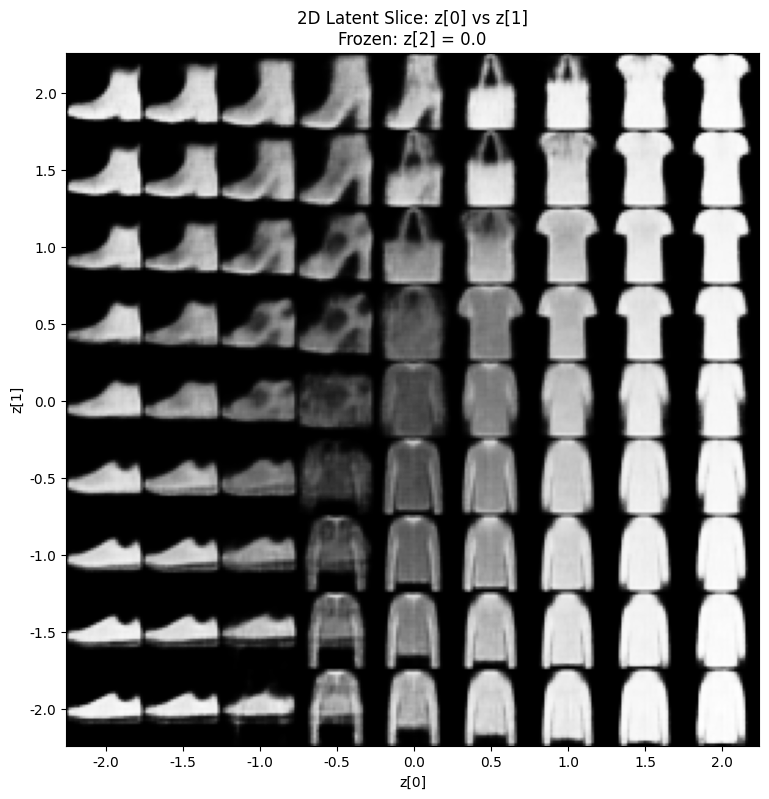

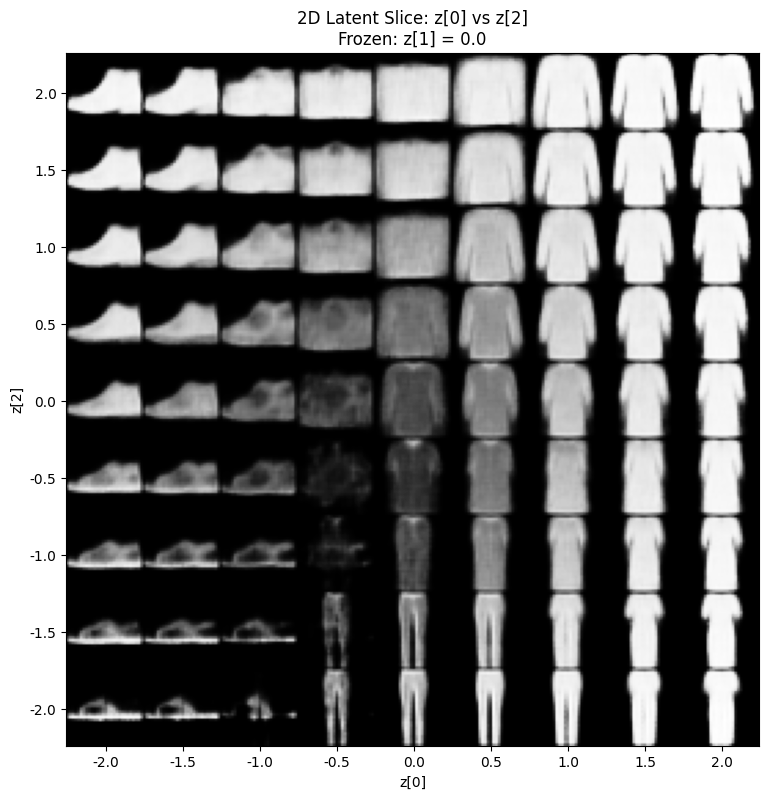

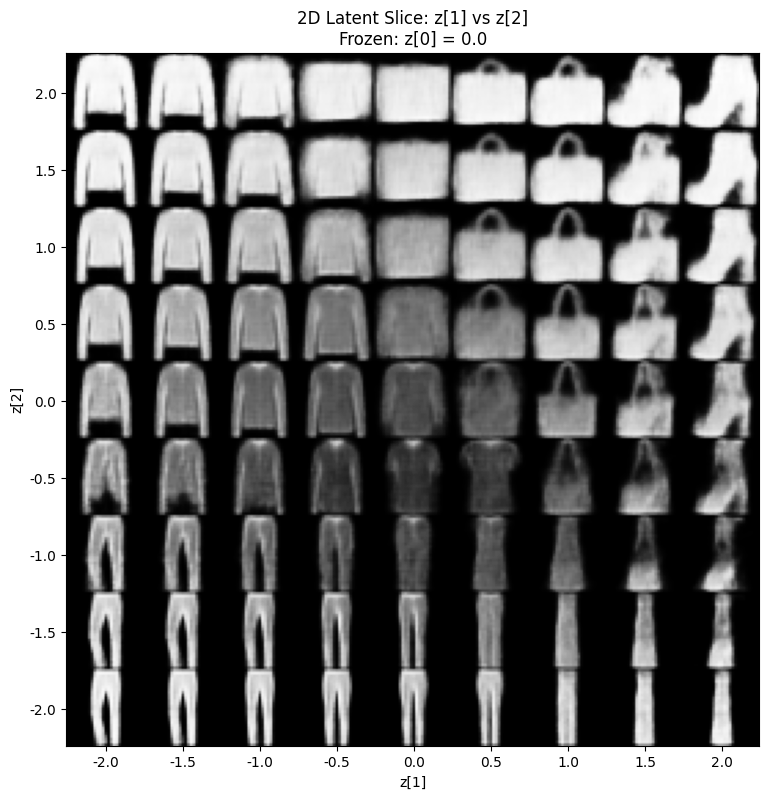

In [29]:
# Pairwise 2D slice matrices for latent_dim = 3

def plot_pairwise_latent_slice(vae, dim_x, dim_y, frozen_dim, frozen_value=0.0):
    latent_dim = vae.decoder.input_shape[-1]
    digit_size = 28

    # Values are centred around 0 because of KL regularisation
    values = np.array([-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0])
    n = len(values)

    figure = np.zeros((digit_size * n, digit_size * n))

    for i, y_value in enumerate(values[::-1]):
        for j, x_value in enumerate(values):
            z_sample = np.zeros((1, latent_dim))

            # Vary two selected dimensions
            z_sample[0, dim_x] = x_value
            z_sample[0, dim_y] = y_value

            # Freeze the remaining dimension
            z_sample[0, frozen_dim] = frozen_value

            generated_image = vae.decoder.predict(z_sample, verbose=0)[0].reshape(28, 28)

            figure[
                i * digit_size : (i + 1) * digit_size,
                j * digit_size : (j + 1) * digit_size,
            ] = generated_image

    plt.figure(figsize=(9, 9))

    pixel_range = np.arange(digit_size // 2, digit_size * n, digit_size)

    plt.xticks(pixel_range, values)
    plt.yticks(pixel_range, values[::-1])

    plt.xlabel(f"z[{dim_x}]")
    plt.ylabel(f"z[{dim_y}]")

    plt.title(
        f"2D Latent Slice: z[{dim_x}] vs z[{dim_y}]\n"
        f"Frozen: z[{frozen_dim}] = {frozen_value}"
    )

    plt.imshow(figure, cmap="Greys_r")
    plt.show()


# Show all possible 2D slices of the 3D latent space
plot_pairwise_latent_slice(vae, dim_x=0, dim_y=1, frozen_dim=2, frozen_value=0.0)
plot_pairwise_latent_slice(vae, dim_x=0, dim_y=2, frozen_dim=1, frozen_value=0.0)
plot_pairwise_latent_slice(vae, dim_x=1, dim_y=2, frozen_dim=0, frozen_value=0.0)

### Pairwise 2D Slice Matrix Observation

The three matrices show that meaningful image transitions occur for every pair of latent dimensions.

The `z[0]`–`z[1]` slice shows transitions among footwear, trousers, bags, and upper-body clothing. The `z[0]`–`z[2]` and `z[1]`–`z[2]` slices also contain substantial variation, confirming that `z[2]` contributes to generated shape and class-like appearance.

The transitions remain relatively smooth between neighbouring latent values. This indicates that the improved VAE learned a continuous and structured latent space.

These matrices also demonstrate why one normal 2D grid is insufficient for a 3D model: different pairs of dimensions expose different types of generated outputs.

# 19. Frozen Dimension Value Comparison

The earlier 2D slice fixed the frozen dimension at 0. However, changing the frozen dimension can produce different slices of the latent space.

This section varies `z[0]` and `z[1]` while freezing `z[2]` at different values: `-1.5`, `0.0`, and `1.5`.

This shows how the generated image grid changes when the frozen dimension is set to different values.

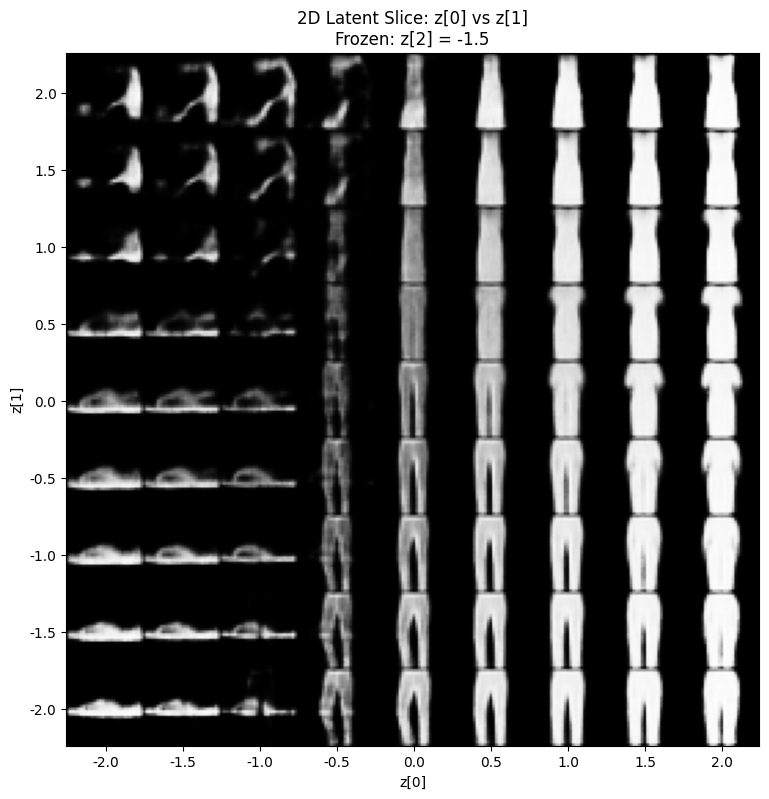

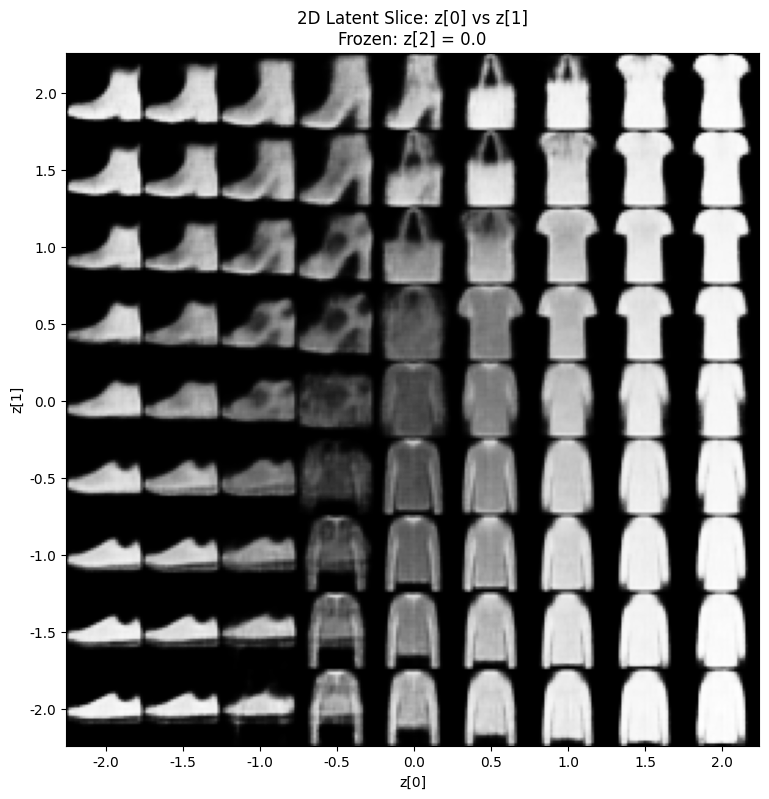

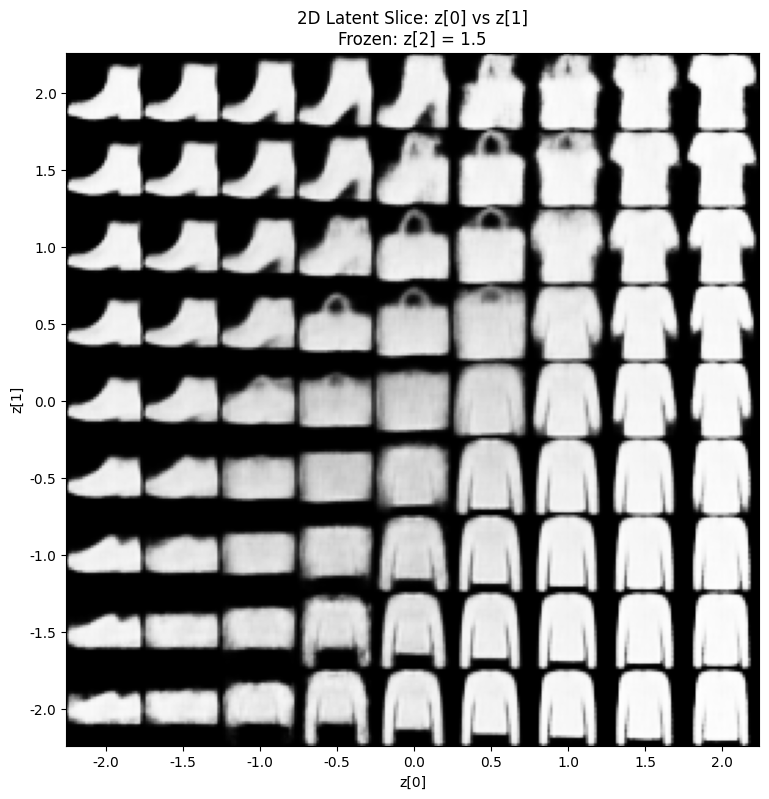

In [30]:
# Compare different frozen values for z[2]

for frozen_value in [-1.5, 0.0, 1.5]:
    plot_pairwise_latent_slice(
        vae,
        dim_x=0,
        dim_y=1,
        frozen_dim=2,
        frozen_value=frozen_value
    )

### Frozen Dimension Comparison Observation

Changing the frozen value of `z[2]` produces visibly different `z[0]`–`z[1]` grids.

When `z[2] = −1.5`, the grid contains more trouser-like and footwear-like outputs. At `z[2] = 0`, a broader mixture of footwear, trousers, bags, and upper-body clothing appears. When `z[2] = 1.5`, more bag-like and upper-body silhouettes become visible.

This confirms that `z[2]` changes the region of the latent space being viewed. A generated grid with `z[2]` fixed at 0 therefore represents only one possible slice and not the complete behaviour of the improved VAE.

# 20. Generate All Fashion MNIST Classes

This experiment checks whether the improved decoder can generate all 10 Fashion MNIST classes.

The method used is:

1. Encode Fashion MNIST training images into the latent space.
2. Find the average latent vector for each class.
3. Decode each class-centre latent vector.
4. Display one generated image for each class.

The Fashion MNIST classes are:

| Label | Class |
|---|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

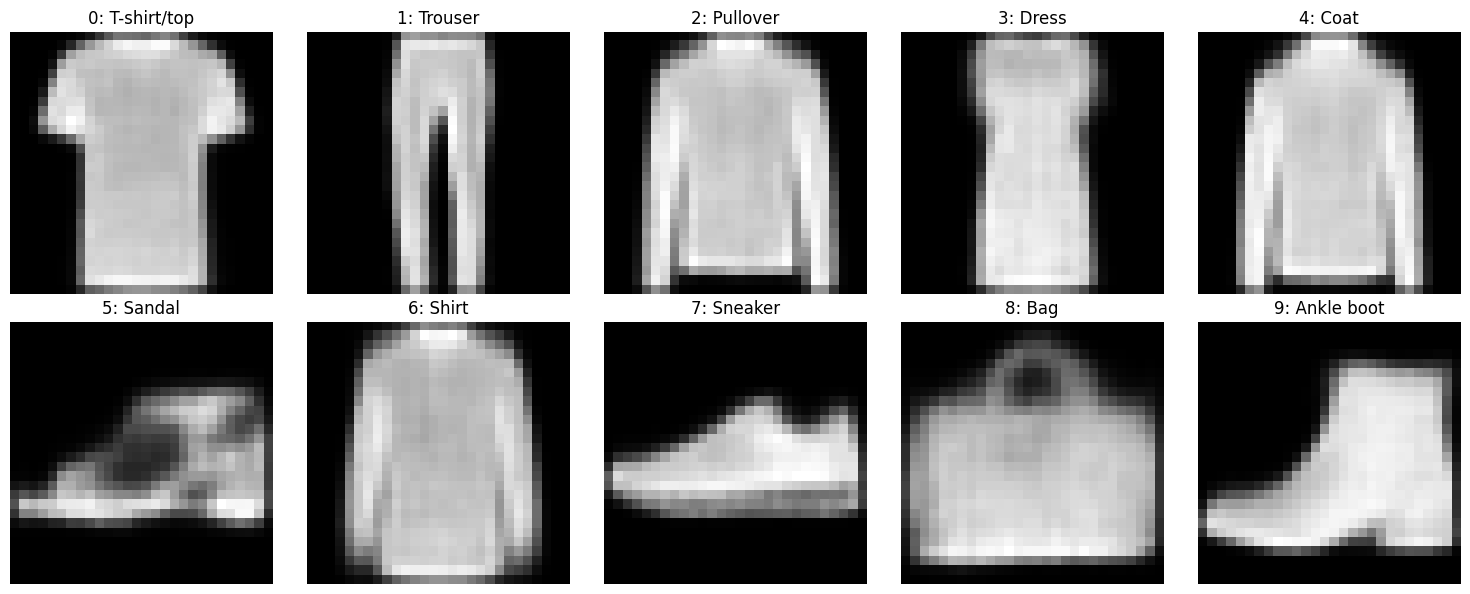

In [31]:
(x_train, y_train), _ = keras.datasets.fashion_mnist.load_data()
x_train = np.expand_dims(x_train, -1).astype("float32") / 255

z_mean, _, _ = vae.encoder.predict(x_train, verbose=0)

decoded_images = []

for class_id in range(10):
    class_vectors = z_mean[y_train == class_id]
    class_centre = class_vectors.mean(axis=0)

    decoded = vae.decoder.predict(class_centre.reshape(1, -1), verbose=0)
    decoded_image = decoded[0].reshape(28, 28)

    decoded_images.append(decoded_image)

plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(decoded_images[i], cmap="gray")
    plt.title(f"{i}: {fashion_class_names[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Class-Centre Generation Observation

The improved decoder produced a Fashion MNIST-like prototype for all 10 class-centre latent vectors.

Trouser, Sneaker, Bag, and Ankle boot are particularly recognisable because they have distinctive silhouettes. T-shirt/top, Pullover, Dress, Coat, and Shirt are also represented, although their generated prototypes remain visually similar. The Sandal prototype is recognisable but less sharply defined.

This demonstrates that class-related information for all 10 labels is present in the learned representation.

However, class-centre generation is label-informed because the known labels are used to calculate each average latent vector. It demonstrates class coverage within the encoded representation, but it does not prove that random latent sampling generates all classes equally.

# 21. Save Model Weights

The improved VAE model weights are saved so that the model can be loaded later without retraining.

In [32]:
vae.save_weights("vae_fashion_improved_latent3.weights.h5")
encoder.save_weights("encoder_fashion_improved_latent3.weights.h5")
decoder.save_weights("decoder_fashion_improved_latent3.weights.h5")

# 22. Additional Comparison: Normal Autoencoder vs VAE

This section trains a normal autoencoder on Fashion MNIST and compares it with the VAE model.

A normal autoencoder learns to reconstruct input images by compressing them into a latent vector and decoding them back into images. Unlike a VAE, it does not use `z_mean`, `z_log_var`, sampling, or KL loss. Therefore, its latent space is not forced to follow a smooth probability distribution.

The comparison helps show the difference between reconstruction-focused autoencoders and generation-focused VAEs.

In [33]:
# Reuse the existing NumPy, Matplotlib, TensorFlow,
# Keras and layers imports from the start of the notebook.

# Load Fashion MNIST again to make this section self-contained
(x_train_ae, y_train_ae), (x_test_ae, y_test_ae) = (
    keras.datasets.fashion_mnist.load_data()
)

# Normalise and reshape
x_train_ae = np.expand_dims(
    x_train_ae,
    -1
).astype("float32") / 255.0

x_test_ae = np.expand_dims(
    x_test_ae,
    -1
).astype("float32") / 255.0

print("x_train_ae shape:", x_train_ae.shape)
print("x_test_ae shape:", x_test_ae.shape)

x_train_ae shape: (60000, 28, 28, 1)
x_test_ae shape: (10000, 28, 28, 1)


# 23. Build Normal Autoencoder

The normal autoencoder uses the same latent dimension as the improved VAE, `latent_dim = 3`. This keeps the bottleneck size consistent, although the comparison remains illustrative because the two models have different objectives and training arrangements.

The encoder compresses the Fashion MNIST image into a 3-dimensional latent vector. The decoder reconstructs the image from this latent vector.

In [34]:
latent_dim_ae = 3

# Autoencoder Encoder
ae_encoder_inputs = keras.Input(shape=(28, 28, 1), name="ae_encoder_input")

x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(ae_encoder_inputs)
x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)

x = layers.Flatten()(x)
x = layers.Dense(32, activation="relu")(x)

ae_latent_vector = layers.Dense(latent_dim_ae, name="ae_latent_vector")(x)

ae_encoder = keras.Model(ae_encoder_inputs, ae_latent_vector, name="normal_autoencoder_encoder")
ae_encoder.summary()

Model: "normal_autoencoder_encoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 ae_encoder_input (InputLaye  [(None, 28, 28, 1)]      0         
 r)                                                              
                                                                 
 conv2d_3 (Conv2D)           (None, 14, 14, 32)        320       
                                                                 
 conv2d_4 (Conv2D)           (None, 14, 14, 32)        9248      
                                                                 
 conv2d_5 (Conv2D)           (None, 7, 7, 64)          18496     
                                                                 
 flatten_1 (Flatten)         (None, 3136)              0         
                                                                 
 dense_2 (Dense)             (None, 32)                100384    
                                        

In [35]:
# Autoencoder Decoder
ae_latent_inputs = keras.Input(shape=(latent_dim_ae,), name="ae_latent_input")

x = layers.Dense(7 * 7 * 64, activation="relu")(ae_latent_inputs)
x = layers.Reshape((7, 7, 64))(x)

x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)

ae_decoder_outputs = layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")(x)

ae_decoder = keras.Model(ae_latent_inputs, ae_decoder_outputs, name="normal_autoencoder_decoder")
ae_decoder.summary()

Model: "normal_autoencoder_decoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 ae_latent_input (InputLayer  [(None, 3)]              0         
 )                                                               
                                                                 
 dense_3 (Dense)             (None, 3136)              12544     
                                                                 
 reshape_1 (Reshape)         (None, 7, 7, 64)          0         
                                                                 
 conv2d_transpose_4 (Conv2DT  (None, 14, 14, 64)       36928     
 ranspose)                                                       
                                                                 
 conv2d_transpose_5 (Conv2DT  (None, 14, 14, 32)       18464     
 ranspose)                                                       
                                        

In [36]:
# Build complete normal autoencoder
ae_outputs = ae_decoder(ae_encoder(ae_encoder_inputs))

autoencoder = keras.Model(ae_encoder_inputs, ae_outputs, name="normal_autoencoder")

autoencoder.compile(
    optimizer=keras.optimizers.Adam(),
    loss="binary_crossentropy"
)

autoencoder.summary()

Model: "normal_autoencoder"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 ae_encoder_input (InputLaye  [(None, 28, 28, 1)]      0         
 r)                                                              
                                                                 
 normal_autoencoder_encoder   (None, 3)                128547    
 (Functional)                                                    
                                                                 
 normal_autoencoder_decoder   (None, 28, 28, 1)        77473     
 (Functional)                                                    
                                                                 
Total params: 206,020
Trainable params: 206,020
Non-trainable params: 0
_________________________________________________________________


### Normal Autoencoder Architecture Observation

The normal autoencoder contains **206,020 trainable parameters** and uses the same 3-dimensional bottleneck as the improved VAE.

Its decoder architecture is identical in size to the improved VAE decoder, with **77,473 parameters**. Its encoder contains **128,547 parameters**, which is only 99 fewer than the improved VAE encoder.

The small parameter difference occurs because the VAE requires separate `z_mean` and `z_log_var` outputs, while the normal autoencoder produces only one deterministic latent vector.

Therefore, the two models have nearly equal architectural capacity. Their main differences are the VAE sampling process, KL regularisation and training arrangement, rather than a major difference in parameter count.

# 24. Train Normal Autoencoder

The normal autoencoder is trained to reconstruct Fashion MNIST images. Unlike the VAE, it only uses reconstruction loss and does not include KL loss.

In [37]:
ae_history = autoencoder.fit(
    x_train_ae,
    x_train_ae,
    epochs=30,
    batch_size=128,
    validation_data=(x_test_ae, x_test_ae)
)

Epoch 1/30
469/469 [==============================] - 16s 30ms/step - loss: 0.3653 - val_loss: 0.3243
Epoch 2/30
469/469 [==============================] - 12s 26ms/step - loss: 0.3176 - val_loss: 0.3171
Epoch 3/30
469/469 [==============================] - 20s 42ms/step - loss: 0.3137 - val_loss: 0.3148
Epoch 4/30
469/469 [==============================] - 11s 24ms/step - loss: 0.3113 - val_loss: 0.3123
Epoch 5/30
469/469 [==============================] - 11s 23ms/step - loss: 0.3098 - val_loss: 0.3116
Epoch 6/30
469/469 [==============================] - 10s 22ms/step - loss: 0.3085 - val_loss: 0.3099
Epoch 7/30
469/469 [==============================] - 11s 23ms/step - loss: 0.3076 - val_loss: 0.3094
Epoch 8/30
469/469 [==============================] - 24s 52ms/step - loss: 0.3068 - val_loss: 0.3091
Epoch 9/30
469/469 [==============================] - 31s 66ms/step - loss: 0.3062 - val_loss: 0.3078
Epoch 10/30
469/469 [==============================] - 33s 71ms/step - loss: 0.305

### Autoencoder Training Observation

The normal autoencoder completed 30 epochs using a 3-dimensional bottleneck.

The training binary cross-entropy decreased from approximately **0.3653** in epoch 1 to **0.3006** in epoch 30. The validation loss decreased from approximately **0.3243** to **0.3038**.

The relatively small gap between training and validation loss suggests that the autoencoder did not show severe overfitting during this run.

These loss values should not be compared numerically with the VAE reconstruction-loss values because the autoencoder uses an averaged binary cross-entropy, while the VAE reconstruction loss is summed across image pixels and also includes separate KL regularisation.

# 25. Autoencoder Reconstruction

Ten Fashion MNIST test images are passed through the normal autoencoder.

The first row displays the original images, while the second row displays their reconstructions. This checks how well the 3-dimensional deterministic bottleneck preserves the shape and class identity of existing images.

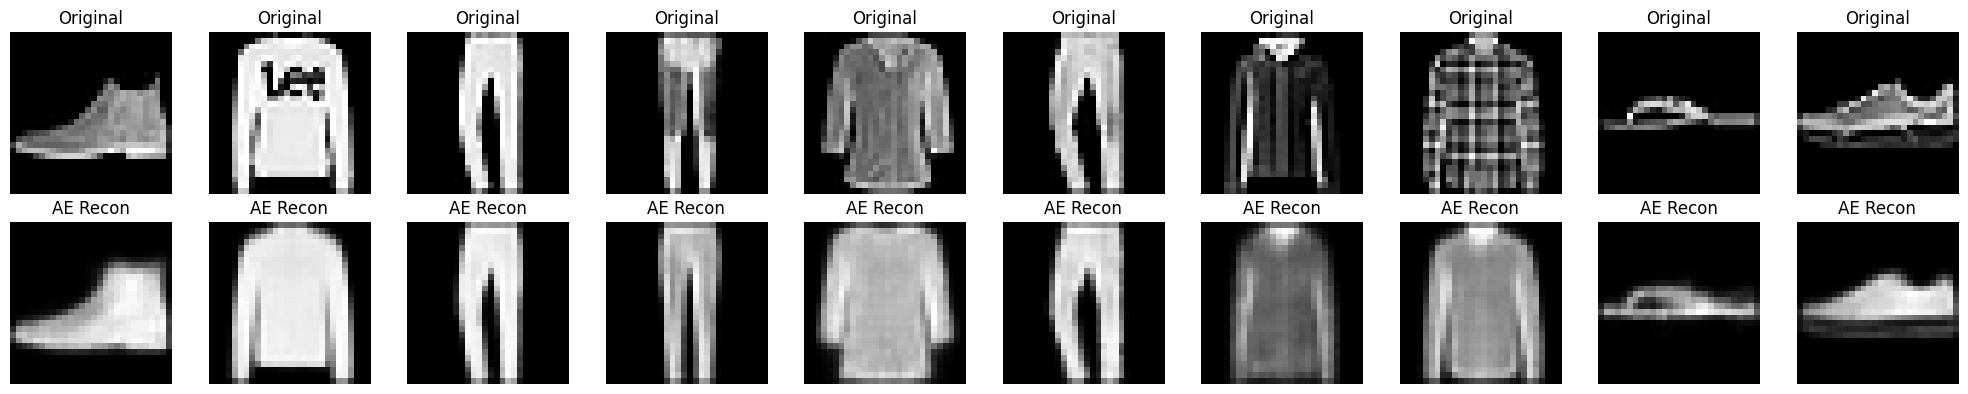

In [38]:
# Select test images
n = 10
test_images_ae = x_test_ae[:n]

# Reconstruct using normal autoencoder
reconstructed_ae = autoencoder.predict(test_images_ae, verbose=0)

plt.figure(figsize=(20, 4))

for i in range(n):
    # Original images
    plt.subplot(2, n, i + 1)
    plt.imshow(test_images_ae[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed images
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed_ae[i].reshape(28, 28), cmap="gray")
    plt.title("AE Recon")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Autoencoder Reconstruction Observation

The normal autoencoder preserves the main silhouettes and class identities of the selected Fashion MNIST images.

Trousers, footwear, bags, and upper-body clothing remain recognisable after reconstruction. Some details are smoothed or blurred because each image is compressed into only three latent values.

The results show that the deterministic autoencoder can reconstruct existing images effectively, although reconstruction quality varies between individual examples.

# 26. VAE vs Autoencoder Reconstruction

The same Fashion MNIST images are reconstructed using both models.

For the VAE, `z_mean` is used to obtain a deterministic reconstruction without sampling noise. This makes the visual comparison more stable.

The rows display:

1. Original images
2. Improved VAE reconstructions
3. Normal autoencoder reconstructions

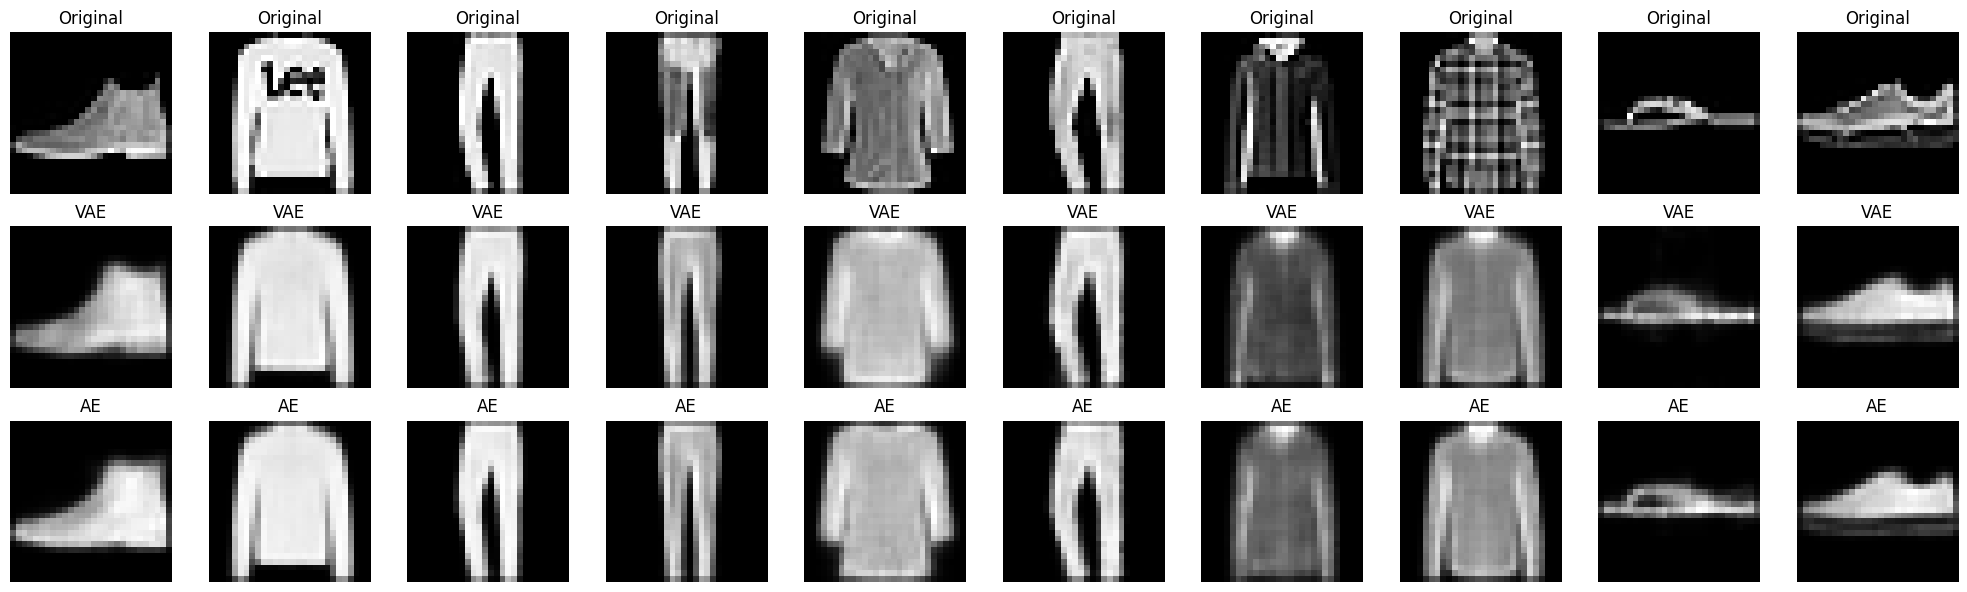

In [39]:
# Compare Original vs VAE Reconstruction vs Normal Autoencoder Reconstruction

n = 10
compare_images = x_test_ae[:n]

# VAE reconstruction using z_mean from the improved VAE encoder
z_mean_compare, _, _ = vae.encoder.predict(compare_images, verbose=0)
vae_reconstructed = vae.decoder.predict(z_mean_compare, verbose=0)

# Normal autoencoder reconstruction
ae_reconstructed = autoencoder.predict(compare_images, verbose=0)

plt.figure(figsize=(20, 6))

for i in range(n):
    # Original
    plt.subplot(3, n, i + 1)
    plt.imshow(compare_images[i].reshape(28, 28), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # VAE reconstruction
    plt.subplot(3, n, i + 1 + n)
    plt.imshow(vae_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("VAE")
    plt.axis("off")

    # Autoencoder reconstruction
    plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(ae_reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("AE")
    plt.axis("off")

plt.tight_layout()
plt.show()

### VAE vs Autoencoder Reconstruction Observation

Both models preserve the main shapes of the original Fashion MNIST items.

The normal autoencoder produces relatively direct reconstructions because its objective focuses entirely on rebuilding the input. The VAE reconstructions are generally smoother because the VAE must balance reconstruction quality with KL regularisation of the latent space.

Neither model is uniformly sharper for every example. The main distinction is therefore not only visual sharpness: the normal autoencoder learns a deterministic reconstruction space, while the VAE learns a regularised latent space designed for meaningful sampling and interpolation.

# 27. Random Generation

Ten latent vectors are sampled independently from a standard normal distribution and passed directly into the normal autoencoder decoder.

Unlike the VAE, the normal autoencoder was not trained to make its latent vectors follow this distribution. Therefore, random normal vectors may fall in regions that do not correspond to valid Fashion MNIST images.

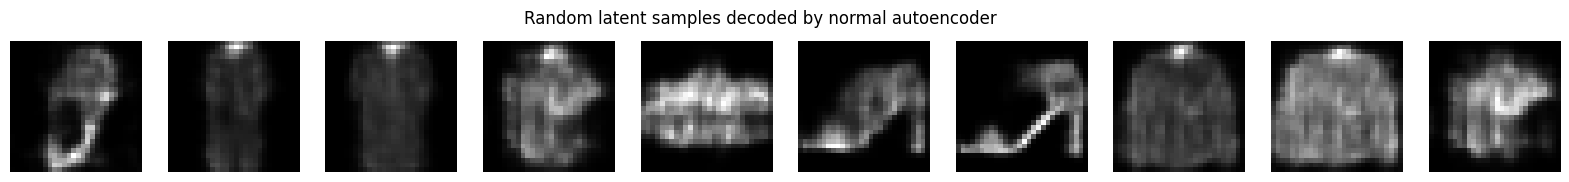

In [40]:
# Generate random latent vectors
random_latent_vectors = np.random.normal(size=(10, latent_dim_ae))

# Decode random latent vectors using the normal autoencoder decoder
random_generated_ae = ae_decoder.predict(random_latent_vectors, verbose=0)

plt.figure(figsize=(20, 2))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(random_generated_ae[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Random latent samples decoded by normal autoencoder")
plt.show()

### Random Generation Observation

Most randomly generated autoencoder outputs are blurry, ambiguous, or only partially resemble Fashion MNIST items.

This occurs because the normal autoencoder does not regularise its latent vectors towards a known probability distribution. A random vector drawn from `N(0,1)` is therefore not guaranteed to lie near the encoded representation of a real item.

In contrast, the VAE explicitly regularises its latent space through `z_mean`, `z_log_var`, sampling, and KL loss. This makes the VAE more suitable for random generation and smooth latent-space exploration.

### Save Normal Autoencoder Weights

The encoder, decoder, and complete normal autoencoder weights are saved so that the trained models can be reused without repeating the 30-epoch training process.

In [41]:
ae_encoder.save_weights("normal_autoencoder_encoder_fashion_latent3.weights.h5")
ae_decoder.save_weights("normal_autoencoder_decoder_fashion_latent3.weights.h5")
autoencoder.save_weights("normal_autoencoder_fashion_latent3.weights.h5")

# 28. Autoencoder vs VAE Conclusion

The normal autoencoder and the VAE both use encoder-decoder architectures, but they optimise different objectives.

The normal autoencoder is trained only to reconstruct its input. It therefore learns a deterministic compressed representation that can preserve existing image shapes effectively. However, its latent space is not forced to follow a smooth or known distribution.

The VAE balances reconstruction loss with KL regularisation. Its reconstructions may appear smoother, but its latent space is continuous, regularised, and suitable for sampling, interpolation, and controlled generation.

The random-generation experiment supports this distinction. Random normal vectors produced mostly ambiguous outputs when passed through the normal autoencoder decoder, while the VAE generated structured Fashion MNIST-like transitions across its latent space.

Therefore, the normal autoencoder is reconstruction-focused, while the VAE is better suited to generative modelling.

# 29. Final Conclusion

Experiment 5 improved the Fashion MNIST VAE architecture while keeping `latent_dim = 3` fixed as a balanced and interpretable setting.

The improved VAE completed 30 training epochs and achieved a final reconstruction loss of approximately **238.82**. In the deterministic common-set comparison, its mean reconstruction BCE was approximately **238.89**, compared with **255.94** for the baseline VAE. This represents a reduction of approximately **6.66%**, and approximately **94.62%** of the evaluated images were reconstructed with lower error.

The per-class analysis showed that the improvement occurred across all 10 Fashion MNIST categories. Bag achieved the largest median error reduction, Trouser had the lowest improved-model median error, and Pullover remained the most difficult class to reconstruct.

The improved latent representation used all three dimensions meaningfully. Their standard deviations were approximately `1.0189`, `1.0174`, and `0.9951`, compared with the earlier baseline model where the third dimension became nearly inactive.

The direct plots, pairwise projections, t-SNE, class-wise violin plots, variation matrices, and frozen-dimension experiments showed that each latent dimension contributes to generated shape and class-like appearance. In particular, changing `z[2]` produced substantial changes, confirming that the improved architecture made better use of the full 3D latent space.

Class-centre decoding produced Fashion MNIST-like prototypes for all 10 labels, although visually similar upper-body classes continued to overlap and remained more difficult to distinguish.

The normal autoencoder comparison demonstrated the difference between reconstruction-focused and generation-focused models. The deterministic autoencoder reconstructed existing images effectively, but randomly sampled latent vectors produced mostly ambiguous outputs. The VAE was more suitable for generation because its latent space was regularised and sampleable.

Overall, the improved `latent_dim = 3` VAE produced lower reconstruction error, more complete latent-dimension usage, and a stronger generative analysis than the original baseline model.

### Experimental Limitation

The latent-dimension comparison was based on one training run for each tested value. VAE results can vary because of random weight initialisation, random sampling and mini-batch order.

A more rigorous experiment would train each latent dimension several times using different random seeds, then compare the average reconstruction loss and standard deviation. Therefore, the selected `latent_dim = 3` should be described as a balanced and interpretable choice from this experiment, rather than a universally optimal latent dimension.

The improved VAE was trained using the combined Fashion MNIST training and test images, while the normal autoencoder used the original training set with the test set as validation data. Therefore, their reconstruction comparison is intended to demonstrate the difference between model behaviours rather than provide a strict unseen generalisation comparison.

The baseline and improved VAE reconstruction comparison used images that had already been included in their combined 70,000-image training dataset. Therefore, the reconstruction BCE comparison measures performance on a common reconstruction set rather than unseen generalisation performance. A stricter future experiment would train both VAEs using only the original training split and evaluate them on an untouched test split.

The improved VAE also contains more parameters than the baseline VAE. The baseline encoder and decoder contain approximately **137,335 parameters** in total, while the improved encoder and decoder contain approximately **206,119 parameters**, an increase of about **50.08%**. Therefore, the lower reconstruction error is achieved with greater model capacity and computational cost. A future comparison could also evaluate training time, inference time and memory usage to determine whether the improvement justifies the additional complexity.